## VIRGA Brown Dwawrfs Atmosphere Modeling - Adding SiO2 + Using Diamondback PT Profile

In [5]:
# Set environment variables for PICASO reference data    
picaso_refdata = "/Users/nguyendat/Documents/GitHub/picaso/reference/"
pysyn_cdbs = "/Users/nguyendat/Documents/GitHub/picaso/reference/stellar_spectra/grp/redcat/trds"
picaso_home = '/Users/nguyendat/Documents/GitHub/picaso/'

import os 
"""Set environment variables for PICASO reference data."""
os.environ['picaso_refdata'] = picaso_refdata
os.environ['PYSYN_CDBS'] = pysyn_cdbs

from picaso import justdoit as jdi
from virga import justdoit as vjdi

import importlib
importlib.reload(vjdi)

#plot tools
from picaso import justplotit as jpi
from virga import justplotit as vjpi

import astropy.units as u
import pandas as pd
from bokeh.plotting import show, figure
from bokeh.io import output_notebook 
output_notebook()

import pickle as pickle
import numpy as np

Loading BokehJS ...

### Function to read Diamondback PT-profile: get closest physical properties.

In [16]:
import re
import math
from io import StringIO

def read_sonora_diamondback(bd, sonora_diamondback_path, teff, fsed=1, mh=0.0, co=1.0,
                             drop_cols=('n', 'e-', 'H+', 'H-')):
    """
    Loads a climate-converged Sonora Diamondback P-T + chemistry profile
    (Morley et al. 2024) directly into a PICASO `inputs` bundle, as a
    drop-in analogue to `bd.sonora()` -- but for the cloudy, RC-converged
    Diamondback grid instead of the cloud-free Bobcat grid.

    File naming convention: t{Teff}g{gravity, m/s2}f{fsed}_m{[M/H]}_co{C/O, xsolar}
    e.g. t900g31f1_m-0.5_co1.0

    File structure (confirmed from an actual .pt file):
      line 1: whitespace-delimited column header
              n P T e- H2 H H+ H- VO TiO CO2 He H2O CH4 CO NH3 N2 PH3 H2S Fe Na K
      line 2: a single scalar -- the gravity in m/s2, redundant with the filename.
              NOT a data row, but has the same number of leading-whitespace-stripped
              tokens as a short/blank line would, so a naive header=0 read silently
              misaligns every subsequent row by one and NaN-pads the rest of that row.
      lines 3+: data, P in bar, T in K, rest are volume mixing ratios.

    This function detects and skips ANY line whose token count doesn't match the
    header's column count (not just line 2 specifically), so it's robust if a
    given file has extra metadata/footer lines elsewhere too.

    Selection logic: nearest available fsed -> nearest available [M/H] -> nearest
    available C/O narrow the candidate files down to one (Teff, gravity) sub-grid,
    then nearest-neighbor in (Teff, gravity) picks the final file. Gravity is
    pulled from whatever `bd.gravity(...)` was already set to (must be called first).

    Parameters
    ----------
    bd : picaso.justdoit.inputs
        Bundle object; bd.gravity(...) must already have been called.
    sonora_diamondback_path : str
        Path to the untarred pressure-temperature_profiles directory.
    teff : float
        Target Teff (K). Grid: 900-2400 K in 100 K steps.
    fsed : float
        Target *background* cloud sedimentation efficiency used to anchor the
        climate-converged P-T structure (grid: 1, 2, 3, 4, 8).
    mh : float
        Target [M/H] (grid: -0.5, 0.0, 0.5).
    co : float
        Target C/O relative to solar (grid currently only has 1.0 = solar).
    drop_cols : tuple of str
        Columns to drop from the Diamondback file before handing off to
        PICASO (level index + charged/ionic species PICASO doesn't carry
        opacities for).

    Returns
    -------
    bd : picaso.justdoit.inputs
        Same bundle, mutated in place (profile, nlevel, sonora_filename set).
    profile : pandas.DataFrame
        The loaded pressure/temperature/chemistry profile.
    """
    try:
        g_mks = bd.inputs['planet']['gravity'] / 100  # cgs (cm/s2) -> m/s2
    except (AttributeError, KeyError):
        raise Exception("Gravity has not been set. Please run bd.gravity(...) first.")

    flist = os.listdir(sonora_diamondback_path)
    flist = [f for f in flist if not f.startswith('._')]

    pattern = re.compile(r'^t(\d+)g(\d+)f(\d+)_m([+-]?\d+(?:\.\d+)?)_co(\d+(?:\.\d+)?)')

    parsed = []
    for f in flist:
        m = pattern.match(f)
        if m:
            t, g, fs, m_h, c_o = m.groups()
            parsed.append({'file': f, 'teff': float(t), 'grav': float(g),
                            'fsed': float(fs), 'mh': float(m_h), 'co': float(c_o)})

    if not parsed:
        raise Exception(f"No Sonora Diamondback profile files could be parsed in "
                         f"{sonora_diamondback_path}. Expected filenames like "
                         f"'t900g31f1_m-0.5_co1.0'. Check the directory contents.")

    grid = pd.DataFrame(parsed)

    for target, col in [(fsed, 'fsed'), (mh, 'mh'), (co, 'co')]:
        avail = grid[col].unique()
        nearest_val = avail[np.argmin(np.abs(avail - target))]
        grid = grid[np.isclose(grid[col], nearest_val)]

    dists = grid.apply(lambda r: math.hypot(r['teff'] - teff, r['grav'] - g_mks), axis=1)
    best = grid.loc[dists.idxmin()]

    filepath = os.path.join(sonora_diamondback_path, best['file'])

    with open(filepath, 'r') as fh:
        raw_lines = fh.readlines()

    header_tokens = raw_lines[0].split()
    ncols = len(header_tokens)

    data_lines, skipped_meta = [], []
    for ln in raw_lines[1:]:
        if not ln.strip():
            continue
        if len(ln.split()) == ncols:
            data_lines.append(ln)
        else:
            skipped_meta.append(ln.strip())

    if skipped_meta:
        print(f"NOTE: skipped {len(skipped_meta)} non-data line(s) in {best['file']} "
              f"whose token count didn't match the {ncols}-column header: {skipped_meta}")
        # sanity-check: the gravity metadata line, if present, should roughly
        # match the gravity implied by the filename
        for s in skipped_meta:
            try:
                sval = float(s)
                if not np.isclose(sval, best['grav'], rtol=0.05):
                    print(f"  WARNING: skipped value {sval} doesn't closely match "
                          f"the filename-implied gravity ({best['grav']} m/s2) -- "
                          f"double check this isn't real data being dropped.")
            except ValueError:
                pass

    # Fix Fortran-style 'D' exponents (e.g. 1.23D-05 -> 1.23E-05) as a safety net
    raw_text_fixed = re.sub(r'(\d)[dD]([+-]?\d)', r'\1E\2', ''.join(data_lines))
    prof = pd.read_csv(StringIO(raw_text_fixed), sep=r'\s+', header=None, names=header_tokens)
    prof = prof.rename(columns={'P': 'pressure', 'T': 'temperature'})
    prof = prof.drop(columns=[c for c in drop_cols if c in prof.columns])

    for c in prof.columns:
        prof[c] = pd.to_numeric(prof[c], errors='coerce')

    n_nan = int(prof.isna().sum().sum())
    if n_nan > 0:
        bad_cols = prof.columns[prof.isna().any()].tolist()
        print(f"WARNING: {n_nan} NaN value(s) remain after parsing {best['file']}, "
              f"in column(s): {bad_cols}. Inspect the raw file before proceeding.")

    if not (prof['pressure'].is_monotonic_increasing or prof['pressure'].is_monotonic_decreasing):
        print(f"WARNING: pressure column in {best['file']} is not monotonic -- "
              f"check the file wasn't truncated or mis-delimited.")

    bd.inputs['atmosphere']['profile'] = prof
    bd.nlevel = prof.shape[0]
    bd.inputs['atmosphere']['sonora_filename'] = best['file']

    print(f"Loaded Sonora Diamondback profile: {best['file']} "
          f"(Teff={best['teff']:.0f} K, g={best['grav']*100:.0f} cm/s2, "
          f"fsed={best['fsed']:.0f}, [M/H]={best['mh']:+.1f}, C/O={best['co']:.2f}x solar), "
          f"{prof.shape[0]} levels, P range [{prof['pressure'].min():.2e}, {prof['pressure'].max():.2e}] bar")

    return bd, prof

In [17]:
### Declare SiO2_amorph
### The default VIRGA call is SiO2 is SiO2_alpha (the SiO2_alpha and SiO2 mieff files are identical)
import virga.gas_properties as gas_properties
import virga.pvaps as pvaps

optical_prop_dir = os.path.join(picaso_home, 'data', 'virga')   # contains virga's .refrind and .mieff files
# check if SiO2_amorph exist, if not, calculate it
if not os.path.exists(os.path.join(optical_prop_dir, 'SiO2_amorph.mieff')):
    print("SiO2_amorph.mieff file not found. Calculating...")

    qext, qscat, g_qscat, radii, wave = vjdi.calc_mie_db(
        ['SiO2_amorph'],
        optical_prop_dir,
        optical_prop_dir
    )

def SiO2_amorph_virga(mw_atmos, mh=1, gas_mmr=None):
    """Amorphous silica: same vapor budget/condensation curve as SiO2
    (Virga treats all SiO2 polymorphs as sharing one saturation vapor
    pressure curve, per Moran+2024 Sec 3.1), but with amorphous density."""
    if gas_mmr is None:
        gas_mmr = 60.3e-6 * mh
    gas_mw = 60
    gas_mmr = gas_mmr * (gas_mw / mw_atmos)
    rho_p = 2.20  # Moran+2024 Table 1
    return gas_mw, gas_mmr, rho_p

def SiO2_amorph(temp, mh=1):
    """Saturation vapor pressure for amorphous SiO2.

    Parameters
    ----------
    temp : float or ndarray
        Temperature (K)
    mh : float
        Metallicity relative to solar (1 = 1X solar).

    Returns
    -------
    float or ndarray
        Vapor pressure in dyn/cm^2.
    """
    mh = np.log10(mh)

    pvap_sio2 = 10.0**(13.168 - 28265.0 / temp - mh)

    # bar -> dyn/cm^2
    return 1e6 * pvap_sio2

# monkey-patch so Atmosphere()/compute() can find SiO2_amorph by name
gas_properties.SiO2_amorph = SiO2_amorph_virga
pvaps.SiO2_amorph = SiO2_amorph

### Configure Picaso atmosphere case function

In [169]:
#point to where you untared your sonora profiles
sonora_profile_db = '/Users/nguyendat/Documents/GitHub/picaso/data/sonora_profile/'
# point to the untarred "pressure-temperature_profiles" folder from the Sonora
sonora_diamondback_profile_db = '/Users/nguyendat/Documents/GitHub/picaso/data/sonora_diamondback_profile/'

### setup for w1741: 
# T=1450K, logg=4.65, R=1.2Rjup, 
# M=27.2MJup, L7 spectral type, C/O=0, M/H=1.0, kzz=5e5

def configure_atm(C_to_O=1.00, mh=1.0, Teff=1400,
                  gravity=10**5, kzz=1e8, phase=0, wave_range=[0.3,15], 
                  background='diamondback', fsed=1, eq=True, excluded_mol=None):
    """
    This function configures a brown dwarf atmosphere with the following inputs:
    C_to_O: float, carbon to oxygen ratio, relative to solar, default: 1.0, solar
    mh: float, metallicity in [M/H] relative to solar, default: 1.0, solar.  VIRGA BROWN DWARF WILL GIVE ERROR FOR MH.
    Teff: int, effective temperature in Kelvin
    gravity: float, surface gravity in m/s^2
    kzz: float, vertical mixing coefficient in cm^2/s
    phase: float, phase angle in radians
    wave_range: list, wavelength range in microns [min, max]
    background: str, 'diamondback' (default) or 'bobcat'.
        'diamondback' loads a climate-converged (RC-equilibrium) Sonora
        Diamondback P-T + chemistry structure anchored at `fsed` -- use this
        if you plan to sweep VIRGA's own fsed over a narrow range around that
        anchor, so the background thermal structure is self-consistent with
        the cloud regime you're actually modeling.
        'bobcat' reproduces the original cloud-free Sonora Bobcat behavior
        (nearest Teff/gravity neighbor), with chemistry from either
        chemeq_visscher (eq=True) or the packaged low-T grid (eq=False).
    fsed: float, only used if background='diamondback'. Which converged
        Diamondback cloud structure to anchor to (grid: 1, 2, 3, 4, 8).
    eq: chem_eq visscher, chem-equilibrium if true
    """
    
    opa = jdi.opannection(wave_range=wave_range) # define opacity range
    bd = jdi.inputs(calculation='browndwarf') # define brown dwarf model/ use no star
    bd.phase_angle(phase) #radians #phase angle of 0 is full phase
    bd.gravity(gravity=gravity, gravity_unit=u.Unit('cm/(s**2)')) #any astropy units available

    if background == 'diamondback':
        # Diamondback filenames encode [M/H] in dex (log10 relative to solar), but this
        # function's `mh` argument follows PICASO's linear-ratio-to-solar convention
        # (mh=1.0 -> solar), same as C_to_O. Convert before matching against the grid.
        if mh <= 0:
            raise ValueError("mh must be > 0 (it's a linear ratio to solar; log10(mh) "
                            "is taken to match Diamondback's dex-based [M/H] grid).")
        bd, profile = read_sonora_diamondback(bd, sonora_diamondback_profile_db, Teff,
                                           fsed=fsed, mh=np.log10(mh), co=C_to_O)
    elif background == 'bobcat':
        #this function will grab the gravity you have input above and find the nearest neighbor with the 
        #note sonora chemistry grid is on the same opacity grid as our opacities (1060). 
        bd.sonora(sonora_profile_db, Teff) # get sonora profile closest to Teff and input gravity
        if eq: # if using chemical equilibrium
            bd.chemeq_visscher(C_to_O, mh) # compute chemeq with visscher grid
        profile = bd.inputs['atmosphere']['profile']
    else:
        raise ValueError("background must be 'diamondback' or 'bobcat'")

    # Add kzz (vertical mixing) to the profile
    profile['kzz'] = np.ones(profile['pressure'].shape[0])*[kzz]
    profile['kz'] = profile['kzz'].copy() # virga wants it named 'kz' so add it again
    
    bd.atmosphere(df=profile, exclude_mol=excluded_mol) # input the profile

    print('====== Configured a brown dwarf atmosphere with: ======')
    print(f'Background: {background}' + (f' (anchor fsed={fsed})' if background == 'diamondback' else ''))
    print(f'Requested Teff: {Teff} K, log(g): {np.log10(gravity)}, g: {gravity} cm/s^2, C/O: {C_to_O}, [M/H]: {mh}, kzz: {kzz} cm^2/s')
    
    return bd, opa, profile

# let's try to make an atmosphere at 1450K, anchored to the climate-converged
# Sonora Diamondback fsed structure
# bd, opa, profile = configure_atm(fsed=1, eq=True)

bd, opa, profile = configure_atm(Teff=1500, background='bobcat')

print(profile.isna().sum())
print(profile.describe())

fig=figure(y_axis_type="log",x_axis_type='log',  y_range=(1e3, 1e-6))

# Example: plot the Sonora profile gases for CO and CO2 with pressure on y-axis
p = profile['pressure']

print('Profile Gases Molecules:', bd.inputs['atmosphere']['profile'].keys())

fig.line(profile['CO'], p, legend_label='CO', line_width=2, color='red')
fig.line(profile['H2O'], p, legend_label='H2O', line_width=2, color='blue')
fig.line(profile['CH4'], p, legend_label='CH4', line_width=2, color='green')
fig.line(profile['CO2'], p, legend_label='CO2', line_width=2, color='orange')
fig.line(profile['NH3'], p, legend_label='NH3', line_width=2, color='purple')
fig.xaxis.axis_label = "Concentration"
fig.yaxis.axis_label = "Pressure (bar)"
show(fig)

====== Configured a brown dwarf atmosphere with: ======
Background: bobcat
Requested Teff: 1500 K, log(g): 5.0, g: 100000 cm/s^2, C/O: 1.0, [M/H]: 1.0, kzz: 100000000.0 cm^2/s
pressure       0
temperature    0
e-             0
H2             0
H              0
H+             0
H-             0
H2-            0
H2+            0
H3+            0
He             0
H2O            0
CH4            0
CO             0
NH3            0
N2             0
PH3            0
H2S            0
TiO            0
VO             0
Fe             0
FeH            0
CrH            0
Na             0
K              0
Rb             0
Cs             0
CO2            0
HCN            0
C2H2           0
C2H4           0
C2H6           0
SiO            0
MgH            0
OCS            0
Li             0
LiOH           0
LiH            0
LiCl           0
graphite       0
Al             0
CaH            0
kzz            0
kz             0
dtype: int64
         pressure  temperature            e-         H2        

In [170]:
profile.keys()

Index(['pressure', 'temperature', 'e-', 'H2', 'H', 'H+', 'H-', 'H2-', 'H2+',
       'H3+', 'He', 'H2O', 'CH4', 'CO', 'NH3', 'N2', 'PH3', 'H2S', 'TiO', 'VO',
       'Fe', 'FeH', 'CrH', 'Na', 'K', 'Rb', 'Cs', 'CO2', 'HCN', 'C2H2', 'C2H4',
       'C2H6', 'SiO', 'MgH', 'OCS', 'Li', 'LiOH', 'LiH', 'LiCl', 'graphite',
       'Al', 'CaH', 'kzz', 'kz'],
      dtype='object')

### Explore condensation curves of various molecules

In [171]:
#get pyeddy recommendation for which gases to run
metallicity = 1.0
mean_molecular_weight = 2.2
recommended_gases = vjdi.recommend_gas(profile['pressure'], profile['temperature'],
                                     mh=metallicity, mmw=mean_molecular_weight, 
                                     plot=True, plot_width=800, plot_height=600)
print('Recommended gases to run (raw virga output):\n', recommended_gases, '\n')
recommended_gases = [item for item in recommended_gases if item != 'CaAl12O19'] # remove CaAl12O19 as mieff is not in the virga database

# Make sure to check available condensates in virga

# Only these gases have virga Mieff files
# SiO2_alpha is alpha crystalline quartz
available_condensates = ['ZnS', 'TiO2', 'NH3', 'Na2S', 'MnS', 
                        'MgSiO3', 'Mg2SiO4', 'KCl', 'H2O', 'Fe', 
                        'Cr', 'CH4', 'CaTiO3', 'Al2O3','SiO2', 
                        'SiO2_amorph'] 
print('Condensates with mieff:\n', available_condensates, '\n')

# Only keep recommended gases that are also available in virga
available_condensates = [item for item in recommended_gases if item in available_condensates]
print('Filtered recommended condensates with mieff:\n', available_condensates, '\n')


Recommended gases to run (raw virga output):
 ['Al2O3', 'CaAl12O19', 'CaTiO3', 'Cr', 'Fe', 'Mg2SiO4', 'MgSiO3', 'MnS', 'Na2S', 'SiO2', 'TiO2', 'ZnS'] 

Condensates with mieff:
 ['ZnS', 'TiO2', 'NH3', 'Na2S', 'MnS', 'MgSiO3', 'Mg2SiO4', 'KCl', 'H2O', 'Fe', 'Cr', 'CH4', 'CaTiO3', 'Al2O3', 'SiO2', 'SiO2_amorph'] 

Filtered recommended condensates with mieff:
 ['Al2O3', 'CaTiO3', 'Cr', 'Fe', 'Mg2SiO4', 'MgSiO3', 'MnS', 'Na2S', 'SiO2', 'TiO2', 'ZnS'] 



In [172]:
### Overplotting Diamonback + Sonora PT profile

bd22, opa22, profile22 = configure_atm(background='diamondback', fsed=2)
bd44, opa44, profile44 = configure_atm(background='diamondback', fsed=4)

### Plot condensation temperature of some species on top of the P-T profile
from bokeh.palettes import Category10_10  # or Category10_6 for 6 colors

fig = figure(y_axis_type="log",x_axis_type='log', y_range=(1e2, 1e-3), 
             width=800, height=600,
             x_axis_label='Temperature (K)',
             y_axis_label='Pressure (bar)')

gases = ['Cr', 'Fe', 'Al2O3', 'MgSiO3', 'Mg2SiO4', 'SiO2', 'KCl', 'MnS', 'Na2S']
colors = Category10_10[:len(gases)] # get tableau colors up to number of gases

# plot the P-T profile for Bobcat
fig.line(profile['temperature'], profile['pressure'], 
         legend_label='P-T Profile: Bobcat cloudfree', line_width=4, color='black',
         line_dash='dashed')

# plot the P-T profile for Diamondback
fig.line(profile22['temperature'], profile22['pressure'], 
         legend_label='P-T Profile: Diamondback fsed=2', line_width=4, color='gray',
         line_dash='dotted')

fig.line(profile44['temperature'], profile44['pressure'], 
legend_label='P-T Profile: Diamondback fsed=4', line_width=4, color='darkgray',
line_dash='dashed')

for i, gasName in enumerate(gases):
    #grab p,t from eddysed
    pgas, tgas = vjdi.condensation_t(gas_name=gasName, mh=1, mmw=2.2)
    fig.line(tgas, pgas, legend_label=gasName, line_width=1, 
             color=colors[i])

# Make legend interactive
fig.legend.click_policy = "mute"  # or "hide" to hide out instead

show(fig)
    

NOTE: skipped 1 non-data line(s) in t1400g1000f2_m0.0_co1.0.pt whose token count didn't match the 22-column header: ['1000.0000000000000']
Loaded Sonora Diamondback profile: t1400g1000f2_m0.0_co1.0.pt (Teff=1400 K, g=100000 cm/s2, fsed=2, [M/H]=+0.0, C/O=1.00x solar), 91 levels, P range [1.78e-04, 2.03e+02] bar
====== Configured a brown dwarf atmosphere with: ======
Background: diamondback (anchor fsed=2)
Requested Teff: 1400 K, log(g): 5.0, g: 100000 cm/s^2, C/O: 1.0, [M/H]: 1.0, kzz: 100000000.0 cm^2/s
NOTE: skipped 1 non-data line(s) in t1400g1000f4_m0.0_co1.0.pt whose token count didn't match the 22-column header: ['1000.0000000000000']
Loaded Sonora Diamondback profile: t1400g1000f4_m0.0_co1.0.pt (Teff=1400 K, g=100000 cm/s2, fsed=4, [M/H]=+0.0, C/O=1.00x solar), 91 levels, P range [1.78e-04, 2.03e+02] bar
====== Configured a brown dwarf atmosphere with: ======
Background: diamondback (anchor fsed=4)
Requested Teff: 1400 K, log(g): 5.0, g: 100000 cm/s^2, C/O: 1.0, [M/H]: 1.0, kzz:

### Adding clouds

In [173]:
#let's get the cloud free spectrum for reference
clf = bd.spectrum(opa, full_output=True)

def convert_unit(df, R=500):
    x, y = df['wavenumber'], df['thermal']  # wavenumber (cm^-1), erg/cm2/s/cm

    xmicron = 1e4 / x       # wavelength in microns, for pysynphot
    flamy = y * 1e-8        # per Angstrom instead of per cm

    sp = jdi.psyn.ArraySpectrum(xmicron, flamy, waveunits='um', fluxunits='FLAM')
    sp.convert('um')
    sp.convert('Fnu')       # erg/cm2/s/Hz

    wave_um = np.asarray(sp.wave)    # microns -- pysynphot may resort these, don't
    flux_nu = np.asarray(sp.flux)    # assume they're still in the original row order

    wavenum = 1e4 / wave_um          # back to wavenumber (cm^-1), paired correctly with flux_nu

    # sort explicitly by wavenumber ascending -- guarantees x/y stay paired and
    # gives mean_regrid a properly monotonic array regardless of pysynphot's internal order
    order = np.argsort(wavenum)
    wavenum_sorted = wavenum[order]
    flux_nu_sorted = flux_nu[order]

    xg, yg = jdi.mean_regrid(wavenum_sorted, flux_nu_sorted, R=R)  # wavenumber (cm^-1), erg/cm2/s/Hz

    # stash results in .attrs rather than as columns -- xg/yg are a *different length*
    # than df (mean_regrid downsamples), so they can never safely be real columns
    df['fluxnu_wavenumber'] = wavenum_sorted
    df['fluxnu'] = flux_nu_sorted
    df['regridx'] = xg
    df['regridy'] = yg

    return df # unchanged core columns ('wavenumber', 'thermal', etc.) -- configure_cloud
               # and anything else indexing out['wavenumber'] keeps working as before

df = convert_unit(clf)
xg, yg = df['regridx'], df['regridy']
xclf, yclf = jdi.mean_regrid(clf['wavenumber'], clf['thermal'], R=300)

show(jpi.spectrum(xclf, yclf, plot_width=1000, plot_height=300,
                     y_axis_label='Flux (erg/s/cm^2/cm)',
                     x_axis_label='Wavelength (micron)',
                     y_axis_type='linear', x_axis_type='log',
                     title='Spectrum in units (erg/s/cm^2/cm)'))
show(jpi.spectrum(xg, yg, plot_width=1000, plot_height=300,
                     y_axis_label='Flux (erg/s/cm^2/Hz)',
                     x_axis_label='Wavelength (micron)',
                     y_axis_type='linear', x_axis_type='log',
                     title='Spectrum in units (erg/s/cm^2/Hz)'))

In [174]:
### Plot condensation temperature of some species on top of the P-T profile
from bokeh.palettes import Category10_10  # or Category10_6 for 6 colors

fig = figure(y_axis_type="log",x_axis_type='log', y_range=(1e2, 1e-3), 
             width=800, height=600,
             x_axis_label='Temperature (K)',
             y_axis_label='Pressure (bar)')

gases = ['Cr', 'Fe', 'Al2O3', 'MgSiO3', 'Mg2SiO4', 'SiO2', 'KCl', 'MnS', 'Na2S']
colors = Category10_10[:len(gases)] # get tableau colors up to number of gases

# plot the P-T profile
fig.line(profile['temperature'], profile['pressure'], 
         legend_label='P-T Profile', line_width=2, color='black',
         line_dash='dashed')

for i, gasName in enumerate(gases):
    #grab p,t from eddysed
    pgas, tgas = vjdi.condensation_t(gas_name=gasName, mh=1, mmw=2.2)
    fig.line(tgas, pgas, legend_label=gasName, line_width=2, 
             color=colors[i])

# Make legend interactive
fig.legend.click_policy = "mute"  # or "hide" to hide out instead

show(fig)
    

In [175]:
import numpy as np
import astropy.constants as const

def spectrum_to_teff(wavenumber, flux_density, flux_unit='per_cm'):
    """
    Integrate a top-of-atmosphere thermal spectrum to bolometric flux,
    then invert Stefan-Boltzmann to get effective temperature.

    Parameters
    ----------
    wavenumber : array
        Wavenumber grid in cm^-1 (e.g. x_cldy, or out['wavenumber']).
    flux_density : array
        Flux density at each wavenumber point. Units set by `flux_unit`.
    flux_unit : str
        'per_cm' -> erg/s/cm^2/cm   (what you get with conversion=False,
                    i.e. y_cldy from your configure_cloud)
        'per_Hz' -> erg/s/cm^2/Hz   (raw PICASO 'thermal' before any regrid/convert)

    Returns
    -------
    F_bol : float
        Bolometric flux at the top of atmosphere, erg/s/cm^2
    Teff : float
        Effective temperature in Kelvin
    """
    wavenumber = np.asarray(wavenumber)
    flux_density = np.asarray(flux_density)

    c_cgs = const.c.cgs.value  # cm/s
    sigma = const.sigma_sb.cgs.value  # erg/s/cm^2/K^4

    if flux_unit == 'per_cm':
        # convert wavenumber (cm^-1) -> wavelength (cm)
        wave_cm = 1.0 / wavenumber
        order = np.argsort(wave_cm)  # ascending wavelength
        F_bol = np.trapz(flux_density[order], wave_cm[order])

    elif flux_unit == 'per_Hz':
        # convert wavenumber (cm^-1) -> frequency (Hz)
        freq = wavenumber * c_cgs
        order = np.argsort(freq)  # ascending frequency
        F_bol = np.trapz(flux_density[order], freq[order])

    else:
        raise ValueError("flux_unit must be 'per_cm' or 'per_Hz'")

    Teff = (F_bol / sigma) ** 0.25

    return F_bol, Teff

In [176]:
def configure_cloud(df, opacity, mmw=2.2, gases=['MgSiO3','Fe','Mg2SiO4', 'SiO2'],
                    fsed=1, directory='/Users/nguyendat/Documents/GitHub/picaso/data/virga/',
                    conversion=True, R=300):
    """
    This function configures clouds in a brown dwarf atmosphere with the following inputs:
    df: picaso atmosphere object
    opacity: picaso opacity object
    mmw: float, mean molecular weight
    gases: list, list of cloud species to include
    fsed: float, sedimentation efficiency parameter
    directory: str, directory to save cloud files
    """
    if gases == 'recommended':
        gases = available_condensates

    print('Using cloud species:', gases)
    # call virga to compute cloud profile and optical depth
    cld_out = df.virga(gases, directory, fsed = fsed, mmw = mmw)
    # VIRGA BROWN DWARF WILL GIVE ERROR FOR MH metalicity

    out = df.spectrum(opacity, full_output=True)
    out = convert_unit(out, R=R)
    
    if conversion: 
        return out['regridx'], out['regridy'], cld_out, out
    else: 
        x_cldy, y_cldy = jdi.mean_regrid(out['wavenumber'], out['thermal'], R=R)
        return x_cldy, y_cldy, cld_out, out

In [181]:
fsed_list = {'Fe': 4, 'MgSiO3': 4, 'SiO2': 1}
gas = ['Fe', 'MgSiO3', 'SiO2']
x_cldy, y_cldy, cld_out, out = configure_cloud(bd, opa, gases=gas, fsed=fsed_list, conversion=False)

fsed_list1 = {'Fe': 5, 'MgSiO3': 5, 'SiO2': 2}
gas1 = ['Fe', 'MgSiO3', 'SiO2']
x_cldy1, y_cldy1, cld_out1, out1 = configure_cloud(bd, opa, gases=gas1, fsed=fsed_list1, conversion=False)


Using cloud species: ['Fe', 'MgSiO3', 'SiO2']
Using cloud species: ['Fe', 'MgSiO3', 'SiO2']


In [182]:
from bokeh.models import FixedTicker, PrintfTickFormatter

p = jpi.spectrum([x_cldy, x_cldy1],#, x_cldy2],
                 [y_cldy, y_cldy1],# y_cldy2],
                 plot_width=1200, plot_height=400,
                #  y_axis_label='Flux (erg/s/cm^2/Hz)',
                 y_axis_label='Flux (erg/s/cm^2/cm)',
                 x_axis_label='Wavelength (micron)',
                 x_axis_type='log',
                 title='Cloud spectra (Fe, MgSiO3, SiO2) (Bobcat PT)',
                 legend=[str(fsed_list), str(fsed_list1)],#, str(fsed_list2)]
                 palette=['blue', 'red']  # different colors per line
                 )

# jpi.spectrum's line renderers come back in order — set dash style on each
# dashes = ['solid', 'solid']
for renderer, dash in zip(p.renderers, dashes):
    renderer.glyph.line_dash = 'solid'
    renderer.glyph.line_width = 2
p.legend[0].location = 'top_right'

# explicit tick locations -- adjust to whatever range/spacing makes sense for your data
# tick_locs = [1, 1.5, 2, 3, 4, 5, 6,  8,  10,  15]
# p.xaxis.ticker = FixedTicker(ticks=tick_locs)
# p.xaxis.formatter = PrintfTickFormatter(format="%.1f")  # avoids scientific notation
# zoom into x-axis range to (0.9-15)
p.x_range.start = 0.7
# p.x_range.end = 6
p.x_range.end = 12

show(p)

### Plot spectral ratio of two different fsed values
p = jpi.spectrum([x_cldy],
                 [(y_cldy1-y_cldy)/y_cldy],
                 plot_width=1000, plot_height=200,
                 y_axis_label='',
                 x_axis_label='Wavelength (micron)',
                 x_axis_type='log',
                 y_axis_type='linear',
                 title='Ratio of spectra',
                 legend=['Ratio (fsed 1.5/1)'],#, str(fsed_list2)]
                 )
p.legend[0].location = 'top_right'
# explicit tick locations -- adjust to whatever range/spacing makes sense for your data
# tick_locs = [1, 1.5, 2, 3, 4, 5, 6,  8,  10,  15]
# p.xaxis.ticker = FixedTicker(ticks=tick_locs)
# p.xaxis.formatter = PrintfTickFormatter(format="%.1f")  # avoids scientific notation
# zoom into x-axis range to (0.9-15)
p.y_range.start = 0
p.y_range.end = 5
p.x_range.start = 0.7
# p.x_range.end = 6
p.x_range.end = 12

show(p)

In [183]:
F_bol, Teff = spectrum_to_teff(x_cldy, y_cldy, flux_unit='per_cm')
print(f'F_bol = {F_bol:.3e} erg/s/cm^2, Teff = {Teff:.1f} K')

F_bol1, Teff1 = spectrum_to_teff(x_cldy1, y_cldy1, flux_unit='per_cm')
print(f'F_bol = {F_bol1:.3e} erg/s/cm^2, Teff = {Teff1:.1f} K')

F_bol = 5.491e+07 erg/s/cm^2, Teff = 992.0 K
F_bol = 7.269e+07 erg/s/cm^2, Teff = 1064.0 K


In [ ]:
for cld_out in [cld_out, cld_out1]:
    show(vjpi.all_optics(cld_out))

In [22]:
# try different kzz models for same fsed.

gas = ['Fe', 'MgSiO3', 'SiO2']

bdk1, opak1, profilek1 = configure_atm(fsed=4, kzz=1e7)
x_cldyk1, y_cldyk1, cld_outk1, outk1 = configure_cloud(bdk1, opak1, gases=gas, fsed=2.0)
x_cldyk1b, y_cldyk1b, cld_outk1b, outk1b = configure_cloud(bdk1, opak1, gases=gas, fsed=2.5)

bdk2, opak2, profilek2 = configure_atm(fsed=4, kzz=1e6)
x_cldyk2, y_cldyk2, cld_outk2, outk2 = configure_cloud(bdk2, opak2, gases=gas, fsed=2.0)
x_cldyk2b, y_cldyk2b, cld_outk2b, outk2b = configure_cloud(bdk2, opak2, gases=gas, fsed=2.5)


NOTE: skipped 1 non-data line(s) in t1400g1000f4_m0.0_co1.0.pt whose token count didn't match the 22-column header: ['1000.0000000000000']
Loaded Sonora Diamondback profile: t1400g1000f4_m0.0_co1.0.pt (Teff=1400 K, g=100000 cm/s2, fsed=4, [M/H]=+0.0, C/O=1.00x solar), 91 levels, P range [1.78e-04, 2.03e+02] bar
====== Configured a brown dwarf atmosphere with: ======
Background: diamondback (anchor fsed=4)
Requested Teff: 1400 K, log(g): 5.0, g: 100000 cm/s^2, C/O: 1.0, [M/H]: 1.0, kzz: 10000000.0 cm^2/s
Using cloud species: ['Fe', 'MgSiO3', 'SiO2']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:7.62186963176295e-08cm for the 0th gas at the 0th grid point; 1.840497334519706e-07cm for the 1th gas at the 0th grid point; 2.2206531185810964e-07cm for the 2th gas at the 0th grid point; 8.771762901174396e-08cm for the 0th gas at the 1th grid point; 2.1185328794755423

In [23]:
from bokeh.models import FixedTicker, PrintfTickFormatter

p = jpi.spectrum([x_cldyk1, x_cldyk1b, x_cldyk2, x_cldyk2b],
                 [y_cldyk1, y_cldyk1b, y_cldyk2, y_cldyk2b],
                 plot_width=1300, plot_height=400,
                 y_axis_label='Flux (erg/s/cm^2/cm)',
                 x_axis_label='Wavelength (micron)',
                 x_axis_type='log',
                 title='Cloudy spectra with different kzz',
                 legend=['kzz=1e7, fsed=2', 'kzz=1e7, fsed=2.5', 'kzz=1e6, fsed=2', 'kzz=1e6, fsed=2.5',])
p.legend[0].location = 'top_right'

# explicit tick locations -- adjust to whatever range/spacing makes sense for your data

tick_locs = [1, 1.5, 2, 3, 4, 5, 6,  8,  10,  15]
p.xaxis.ticker = FixedTicker(ticks=tick_locs)
p.xaxis.formatter = PrintfTickFormatter(format="%.1f")  # avoids scientific notation
# zoom into x-axis range to (0.9-15)
p.x_range.start = 0.7
p.x_range.end = 15

show(p)

### Plot spectral ratio of two different fsed values
p = jpi.spectrum([x_cldyk1],
                 [(y_cldyk2-y_cldyk1)/y_cldyk1 * 100],
                 plot_width=1300, plot_height=250,
                 y_axis_label='Flux Variation (%)',
                 x_axis_label='Wavelength (micron)',
                 x_axis_type='log',
                 y_axis_type='linear',
                 title='Ratio of spectra',
                 legend=['Ratio (kzz=1e6/1e7)'],#, str(fsed_list2)]
                 )
p.legend[0].location = 'top_right'
# explicit tick locations -- adjust to whatever range/spacing makes sense for your data
tick_locs = [1, 1.5, 2, 3, 4, 5, 6,  8,  10,  15]
p.xaxis.ticker = FixedTicker(ticks=tick_locs)
p.xaxis.formatter = PrintfTickFormatter(format="%.1f")  # avoids scientific notation
# zoom into x-axis range to (0.9-15)
p.y_range.start = -20
p.y_range.end = 150
p.x_range.start = 1.0
p.x_range.end = 15

show(p)

In [28]:
from bokeh.models import FixedTicker, PrintfTickFormatter
from bokeh.layouts import row

# Shared x-axis range
shared_x_range = (0.7, 15)

# -------------------------
# kzz = 1e7
# -------------------------
p1 = jpi.spectrum(
    [x_cldyk1, x_cldyk1b],
    [y_cldyk1, y_cldyk1b],
    plot_width=1200,
    plot_height=300,
    y_axis_label='Flux (erg/s/cm^2/cm)',
    x_axis_label='Wavelength (micron)',
    x_axis_type='log',
    title='kzz = 1e7',
    legend=['kzz=1e7, fsed=2', 'kzz=1e7, fsed=2.5']
)

p1.legend[0].location = 'top_right'

# -------------------------
# kzz = 1e6
# -------------------------
p2 = jpi.spectrum(
    [x_cldyk2, x_cldyk2b],
    [y_cldyk2, y_cldyk2b],
    plot_width=1200,
    plot_height=300,
    y_axis_label='Flux (erg/s/cm^2/cm)',
    x_axis_label='Wavelength (micron)',
    x_axis_type='log',
    title='kzz = 1e6',
    legend=['kzz=1e6, fsed=2', 'kzz=1e6, fsed=2.5']
)

p2.legend[0].location = 'top_right'


# -------------------------
# Shared x-axis formatting
# -------------------------
tick_locs = [1, 1.5, 2, 3, 4, 5, 6, 8, 10, 15]

for p in [p1, p2]:
    p.xaxis.ticker = FixedTicker(ticks=tick_locs)
    p.xaxis.formatter = PrintfTickFormatter(format="%.1f")


# -------------------------
# Synchronize zoom/pan
# -------------------------
from bokeh.models import Range1d

shared_range = Range1d(start=0.7, end=15)

p1.x_range = shared_range
p2.x_range = shared_range


# -------------------------
# Show stacked
# -------------------------
show(column(p1, p2))

In [37]:
# ---------------------------------------------------------
# NOTE: this assumes outk1b/outk2b (etc.) are the dict outputs
# from jdi.compute(..., as_dict=True) inside your configure_cloud()
# function — i.e. the raw virga output, not the picaso-formatted
# cloud arrays. If configure_cloud() only returns cld_out/out as
# opd,w0,g0 arrays, you'll need it to also return as_dict=True output.
# ---------------------------------------------------------

# 1. SiO2 particle radius profile + size distribution, Kzz=1e7 vs 1e6
#    pick at_pressure near where the 8-10um photosphere forms
#    (start around 0.1-1 bar for an L/T transition BD, then adjust
#    once you see where SiO2 actually condenses in your PT profile)
fig, dndr = vjpi.radii(
    [outk1b, outk2b],           # fsed=2.5 runs, kzz=1e7 then kzz=1e6
    gas='SiO2',
    at_pressure=1,            # bars — tune to your SiO2 cloud deck
    compare=True,
    legend=['Kzz=1e7, fsed=2.5', 'Kzz=1e6, fsed=2.5']
)
show(fig)

# 2. Cumulative optical depth by gas (Fe, MgSiO3, SiO2), same comparison
show(vjpi.opd_by_gas(
    [outk1b, outk2b],
    compare=True,
    legend=['Kzz=1e7, fsed=2.5', 'Kzz=1e6, fsed=2.5']
))

# Optional: isolate just SiO2's opacity contribution across the two runs
show(vjpi.opd_by_gas(
    [outk1b, outk2b],
    gas='SiO2',
    compare=True,
    legend=['Kzz=1e7', 'Kzz=1e6']
))

# Optional: MgSiO3's opacity contribution across the two runs
show(vjpi.opd_by_gas(
    [outk1b, outk2b],
    gas='MgSiO3',
    compare=True,
    legend=['Kzz=1e7', 'Kzz=1e6']
))

KeyError: 'mean_particle_r'

In [25]:
"""TESTING DIFFERENT FSED VALUES FOR DIFFERENT SPECIES"""
### Simplest case: L/T transition: thin Fe clouds and normal MgSiO3 clouds

gases = ['Fe', 'MgSiO3', 'SiO2']
fseds = [2, 4, 8, 16] # normal fsed for all species

opa_custom = jdi.opannection(wave_range=[1.0, 15.0]) # define opacity range

# Dict with same values
x0, y0, cld_out0, df_out0 = configure_cloud(
    bd, opa_custom, fsed=fseds[0],
    gases=gases, R=500)

x1, y1, cld_out1, df_out1 = configure_cloud(
    bd, opa_custom, fsed=fseds[1],
    gases=gases, R=500)

x2, y2, cld_out2, df_out2 = configure_cloud(
    bd, opa_custom, fsed=fseds[2],
    gases=gases, R=500)

x3, y3, cld_out3, df_out3 = configure_cloud(
    bd, opa_custom, fsed=fseds[3],
    gases=gases, R=500) 

Using cloud species: ['Fe', 'MgSiO3', 'SiO2']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:4.080563258557076e-09cm for the 0th gas at the 0th grid point; 9.932460399906172e-09cm for the 1th gas at the 0th grid point; 1.1978765871806723e-08cm for the 2th gas at the 0th grid point; 4.660363828567911e-09cm for the 0th gas at the 1th grid point; 1.134633317518195e-08cm for the 1th gas at the 1th grid point; 1.3683048957215843e-08cm for the 2th gas at the 1th grid point; 5.318819799981584e-09cm for the 0th gas at the 2th grid point; 1.2952269537883344e-08cm for the 1th gas at the 2th grid point; 1.561866172470034e-08cm for the 2th gas at the 2th grid point; 6.074172220646109e-09cm for the 0th gas at the 3th grid point; 1.4794756852968365e-08cm for the 1th gas at the 3th grid point; 1.7839165941543793e-08cm for the 2th gas at the 3th grid point; 6.946120089563031e

In [26]:
x4, y4, cld_out4, df_out4 = configure_cloud(
    bd, opa_custom, fsed=1,
    gases=gases, R=500)

x5, y5, cld_out5, df_out5 = configure_cloud(
    bd, opa_custom, fsed=1.5,
    gases=gases, R=500)

Using cloud species: ['Fe', 'MgSiO3', 'SiO2']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:1.9773993935108686e-09cm for the 0th gas at the 0th grid point; 4.8624765379760584e-09cm for the 1th gas at the 0th grid point; 5.862112088799373e-09cm for the 2th gas at the 0th grid point; 2.261897644611635e-09cm for the 0th gas at the 1th grid point; 5.56231763136286e-09cm for the 1th gas at the 1th grid point; 6.705723589108175e-09cm for the 2th gas at the 1th grid point; 2.585632267076694e-09cm for the 0th gas at the 2th grid point; 6.358699312688762e-09cm for the 1th gas at the 2th grid point; 7.665685549951796e-09cm for the 2th gas at the 2th grid point; 2.9577464176632117e-09cm for the 0th gas at the 3th grid point; 7.2741112542814656e-09cm for the 1th gas at the 3th grid point; 8.769099592314638e-09cm for the 2th gas at the 3th grid point; 3.3881810848751817e-

In [27]:
cld_out4.keys()

dict_keys(['pressure', 'pressure_unit', 'temperature', 'temperature_unit', 'wave', 'wave_unit', 'condensate_mmr', 'cond_plus_gas_mmr', 'mean_particle_r', 'droplet_eff_r', 'r_units', 'column_density', 'column_density_unit', 'opd_per_layer', 'single_scattering', 'asymmetry', 'opd_by_gas', 'condensibles', 'scalar_inputs', 'fsed', 'altitude', 'layer_thickness', 'z_unit', 'mixing_length', 'mixing_length_unit', 'kz', 'kz_unit', 'scale_height', 'cloud_deck'])

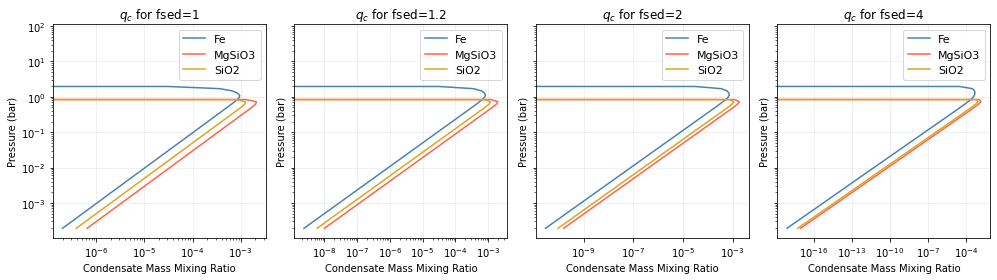

In [28]:
### Plot each column in cld_out3['condensate_mmr'] corresponding to each condensate species for fsed=2, 4
# save = True
save = False
species = ['Fe', 'MgSiO3', 'SiO2']
pressure = cld_out3['pressure']
colors  = ['steelblue', 'tomato', 'goldenrod']
cldouts = [cld_out4, cld_out5, cld_out0, cld_out1]

# function to find cloud deck bounds given condensate mass mixing ratio and pressure profile
### cloud base: Cloud deck "thickness" is defined in pressure space as the range of pressures 
# where the cloud is physically present (i.e., where qc or τ_cloud per layer is non-negligible). 
# A common threshold is where qc falls to ~1% of its peak value, or where the layer τ < 10⁻³.
def cloud_deck_bounds(pressure, qc, threshold_frac=0.01):
    peak = qc.max()
    mask = qc >= threshold_frac * peak
    P_top  = pressure[mask].min()   # lowest pressure = top of deck
    P_base = pressure[mask].max()   # highest pressure = base of deck
    return P_top, P_base

import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 4, figsize=(14, 4), sharey=True)
for j, fss in enumerate([1, 1.2, 2, 4]):
    ax = axs[j]   
    for i, sp in enumerate(species):
        ax.loglog(cldouts[j]['condensate_mmr'][:, i], cldouts[j]['pressure'].reshape(-1), label=sp, color=colors[i])
        # print cloud deck bounds for each species
        P_top, P_base = cloud_deck_bounds(cldouts[j]['pressure'], cldouts[j]['condensate_mmr'][:, i])
        # print(f"fsed={fss}, {sp}: Cloud deck from {P_base:.4f} bar to {P_top:.4f} bar")
    # ax.invert_yaxis()
    # plt.yscale('log')
    ax.set_xlabel('Condensate Mass Mixing Ratio')
    ax.set_ylabel('Pressure (bar)')
    ax.set_title(f'$q_c$ for fsed={fss}')
    ax.legend(fontsize=11)
    ax.grid(True, ls='--', lw=0.5, alpha=0.5, zorder=0)

plt.tight_layout()
if save: 
    plt.savefig('condensate_sio2_mmr_fsed_comparison.pdf', dpi=300, bbox_inches='tight')

fsed=1, Fe: Cloud deck from 1.9637e+00 bar to 3.6746e-02 bar
fsed=1, MgSiO3: Cloud deck from 8.3719e-01 bar to 1.8058e-02 bar
fsed=1, SiO2: Cloud deck from 8.3719e-01 bar to 1.8058e-02 bar
fsed=1.2, Fe: Cloud deck from 1.9637e+00 bar to 1.1452e-01 bar
fsed=1.2, MgSiO3: Cloud deck from 8.3719e-01 bar to 6.4871e-02 bar
fsed=1.2, SiO2: Cloud deck from 8.3719e-01 bar to 6.4871e-02 bar
fsed=2, Fe: Cloud deck from 1.9637e+00 bar to 2.0217e-01 bar
fsed=2, MgSiO3: Cloud deck from 8.3719e-01 bar to 1.1452e-01 bar
fsed=2, SiO2: Cloud deck from 8.3719e-01 bar to 1.1452e-01 bar
fsed=4, Fe: Cloud deck from 1.9637e+00 bar to 4.7423e-01 bar
fsed=4, MgSiO3: Cloud deck from 8.3719e-01 bar to 3.0964e-01 bar
fsed=4, SiO2: Cloud deck from 8.3719e-01 bar to 3.0964e-01 bar


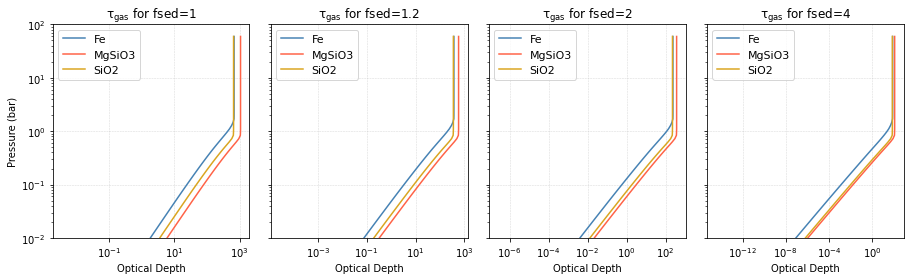

In [29]:
### Plot each column in cld_out3['opd_by_gas'] corresponding to each condensate species for fsed=2, 4
# save = True
save = False
species = ['Fe', 'MgSiO3', 'SiO2']
pressure = cld_out3['pressure']
colors  = ['steelblue', 'tomato', 'goldenrod']
cldouts = [cld_out4, cld_out5, cld_out0, cld_out1]

def cloud_deck_bounds_opd(pressure, opd, abs_floor=1e-3, rel_frac=1e-2):
    peak = opd.max()
    # if cloud is thick, use abs_floor of tau=1e-3, else take 1% of peak tau
    comparison_value = max(rel_frac * peak, abs_floor)
    mask = opd >= comparison_value
    P_top  = pressure[mask].min()
    P_base = pressure[mask].max()
    return P_top, P_base

import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 4, figsize=(12.75, 4), sharey=True)
for j, fss in enumerate([1, 1.2, 2, 4]):
    ax = axs[j]   
    for i, sp in enumerate(species):
        ax.loglog(cldouts[j]['opd_by_gas'][:, i], cldouts[j]['pressure'].reshape(-1), label=sp, color=colors[i])
        # print cloud deck bounds for each species
        P_top, _ = cloud_deck_bounds_opd(cldouts[j]['pressure'], 
                    cldouts[j]['opd_by_gas'][:, i])

        _, P_base = cloud_deck_bounds(cldouts[j]['pressure'], 
                    cldouts[j]['condensate_mmr'][:, i], threshold_frac=0.01)
                    
        print(f"fsed={fss}, {sp}: Cloud deck from {P_base:.4e} bar to {P_top:.4e} bar")
    # ax.invert_yaxis()
    # plt.yscale('log')
    ax.set_xlabel('Optical Depth')
    if j==0: ax.set_ylabel('Pressure (bar)')
    ax.set_title(f'τ$_\mathrm{{gas}}$ for fsed={fss}')
    ax.legend(fontsize=11)
    ax.grid(True, ls='--', lw=0.5, alpha=0.5, zorder=0)
    ax.set_ylim(1e-2, 1e2)

plt.tight_layout()
if save: 
    plt.savefig('opd_by_gas_sio2_fsed_comparison.pdf', dpi=300, bbox_inches='tight')

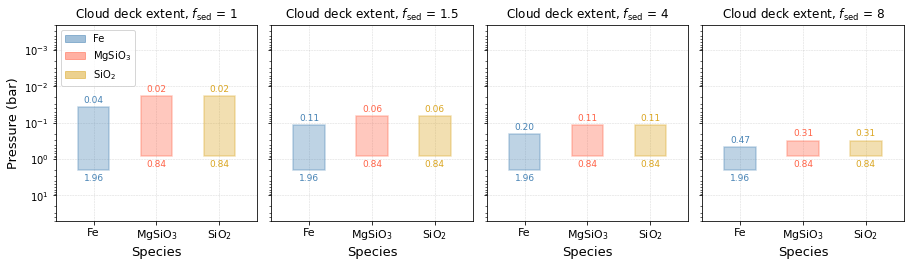

In [37]:
import matplotlib.patches as patches
save = True
# save = False

species   = [f'Fe', f'MgSiO$_3$', f'SiO$_2$']
colors    = ['steelblue', 'tomato', 'goldenrod']
fsed_vals = [1, 1.5, 4, 8]
cldouts   = [cld_out4, cld_out5, cld_out0, cld_out1]

bar_width = 0.5   # x-width of each rectangle (in species-index units)

fig, axs = plt.subplots(1, 4, figsize=(12.75, 3.8), sharey=True)

for j, (ax, fss) in enumerate(zip(axs, fsed_vals)):
    pressure = cldouts[j]['pressure'].reshape(-1)

    for i, (sp, color) in enumerate(zip(species, colors)):
        opd = cldouts[j]['opd_by_gas'][:, i]
        qc = cldouts[j]['condensate_mmr'][:, i]
        P_top, _ = cloud_deck_bounds_opd(pressure, opd)
        _, P_base = cloud_deck_bounds(pressure, qc, threshold_frac=0.01)

        # Rectangle spans x: [i - w/2, i + w/2], y: [P_top, P_base] in data coords
        rect = patches.Rectangle(
            (i - bar_width / 2, P_top),          # (x_left, y_bottom in data)
            bar_width,                             # width
            P_base - P_top,                        # height in data units
            linewidth=1.5,
            edgecolor=color,
            facecolor=color,
            alpha=0.35,
            zorder=2)
        ax.add_patch(rect)

        # Annotate P_top and P_base on the rectangle edges
        ax.text(i, 0.85*P_top,  f'{P_top:.2f}',  ha='center', va='bottom', fontsize=9, color=color)
        ax.text(i, 1.25*P_base, f'{P_base:.2f}', ha='center', va='top',    fontsize=9, color=color)

    ax.set_yscale('log')
    ax.invert_yaxis()
    ax.set_xticks(range(len(species)))
    ax.set_xticklabels(species, fontsize=11)
    ax.set_xlim(-0.6, len(species) - 0.4)
    ax.set_title(f'Cloud deck extent, $f_{{\\rm sed}}$ = {fss}', fontsize=12)
    ax.grid(True, ls='--', lw=0.5, alpha=0.5, zorder=0)
    ax.set_xlabel('Species', fontsize=13)

axs[0].set_ylabel('Pressure (bar)', fontsize=13)
axs[0].set_ylim(50, 2e-4)   # adjust to encompass all decks

# Shared legend
legend_handles = [
    patches.Patch(facecolor=c, edgecolor=c, alpha=0.5, label=s)
    for s, c in zip(species, colors)]

axs[0].legend(handles=legend_handles, loc='upper left', fontsize=10)    
# axs[-1].legend(handles=legend_handles, loc='upper left', fontsize=10)

plt.tight_layout()

if save:
    plt.savefig('cloud_deck_bounds_sio2_fsed_comparison.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
show(jpi.spectrum([x0, x1, x2, x3], [y0, y1, y2, y3], 
                plot_width=1000, plot_height=500,
                y_axis_label='Flux (erg/s/cm^2/Hz)',
                x_axis_label='Wavelength (micron)',
                y_axis_type='linear',
                title='Fsed comparison for clouds',
                legend=[f'fsed={fseds[0]}', 
                        f'fsed={fseds[1]}', 
                        f'fsed={fseds[2]}', 
                        f'fsed={fseds[3]}']))

In [32]:
"""TESTING DIFFERENT FSED VALUES FOR DIFFERENT SPECIES"""
### Simplest case: L/T transition: thin Fe clouds and normal MgSiO3 clouds

gases = ['Fe', 'MgSiO3', 'Na2S']
a0, b0, c0 = 14,   3.1,   4.6
a1, b1, c1 = 14,   3.3,   4.2
a2, b2, c2 = 14,   3.5,   3.8
a3, b3, c3 = 14,   3.7,   3.3
a4, b4, c4 = 14,   3.9,   2.8

fsed_dict0 = {'Fe': a0, 'MgSiO3': b0, 'Na2S': c0}
fsed_dict1 = {'Fe': a1, 'MgSiO3': b1, 'Na2S': c1}
fsed_dict2 = {'Fe': a2, 'MgSiO3': b2, 'Na2S': c2}
fsed_dict3 = {'Fe': a3, 'MgSiO3': b3, 'Na2S': c3}
fsed_dict4 = {'Fe': a4, 'MgSiO3': b4, 'Na2S': c4}

opa_custom = jdi.opannection(wave_range=[1.0, 15.0]) # define opacity range

# Dict with same values
x0, y0, cld_out0, df_out0 = configure_cloud(
    bd, opa_custom, fsed=fsed_dict0,
    gases=gases, R=500)

x1, y1, cld_out1, df_out1 = configure_cloud(
    bd, opa_custom, fsed=fsed_dict1,
    gases=gases, R=500)

x2, y2, cld_out2, df_out2 = configure_cloud(
    bd, opa_custom, fsed=fsed_dict2,
    gases=gases, R=500)

x3, y3, cld_out3, df_out3 = configure_cloud(
    bd, opa_custom, fsed=fsed_dict3,
    gases=gases, R=500)

x4, y4, cld_out4, df_out4 = configure_cloud(
    bd, opa_custom, fsed=fsed_dict4,
    gases=gases, R=500)


Using cloud species: ['Fe', 'MgSiO3', 'Na2S']
Using cloud species: ['Fe', 'MgSiO3', 'Na2S']
Using cloud species: ['Fe', 'MgSiO3', 'Na2S']
Using cloud species: ['Fe', 'MgSiO3', 'Na2S']
Using cloud species: ['Fe', 'MgSiO3', 'Na2S']


In [ ]:
# show(jpi.spectrum([x0, x1, x2], [y0, y1, y2], 
#                 plot_width=1000, plot_height=500,
#                 y_axis_label='Flux (erg/s/cm^2/cm)',
#                 x_axis_label='Wavelength (micron)',
#                 y_axis_type='linear',
#                 title='Fsed per-species Comparison: MgSiO3 and Na2S is anti-correlated',
#                 legend=[f'fe={a0}, si={b0}, s={c0}', 
#                         f'fe={a1}, si={b1}, s={c1}', 
#                         f'fe={a2}, si={b2}, s={c2}']))

show(jpi.spectrum([x0, x1, x2, x3, x4], [y0, y1, y2, y3, y4], 
        plot_width=1000, plot_height=500,
        y_axis_label='Flux (erg/s/cm^2/cm)',
        x_axis_label='Wavelength (micron)',
        y_axis_type='linear',
        title='Fsed per-species Comparison: L/T Transition MgSiO3 and Na2S is anti-correlated',
        legend=[f'fsed: fe={a0}, si={b0}, s={c0}', 
                f'fsed: fe={a1}, si={b1}, s={c1}', 
                f'fsed: fe={a2}, si={b2}, s={c2}',
                f'fsed: fe={a3}, si={b3}, s={c3}',
                f'fsed: fe={a4}, si={b4}, s={c4}']))

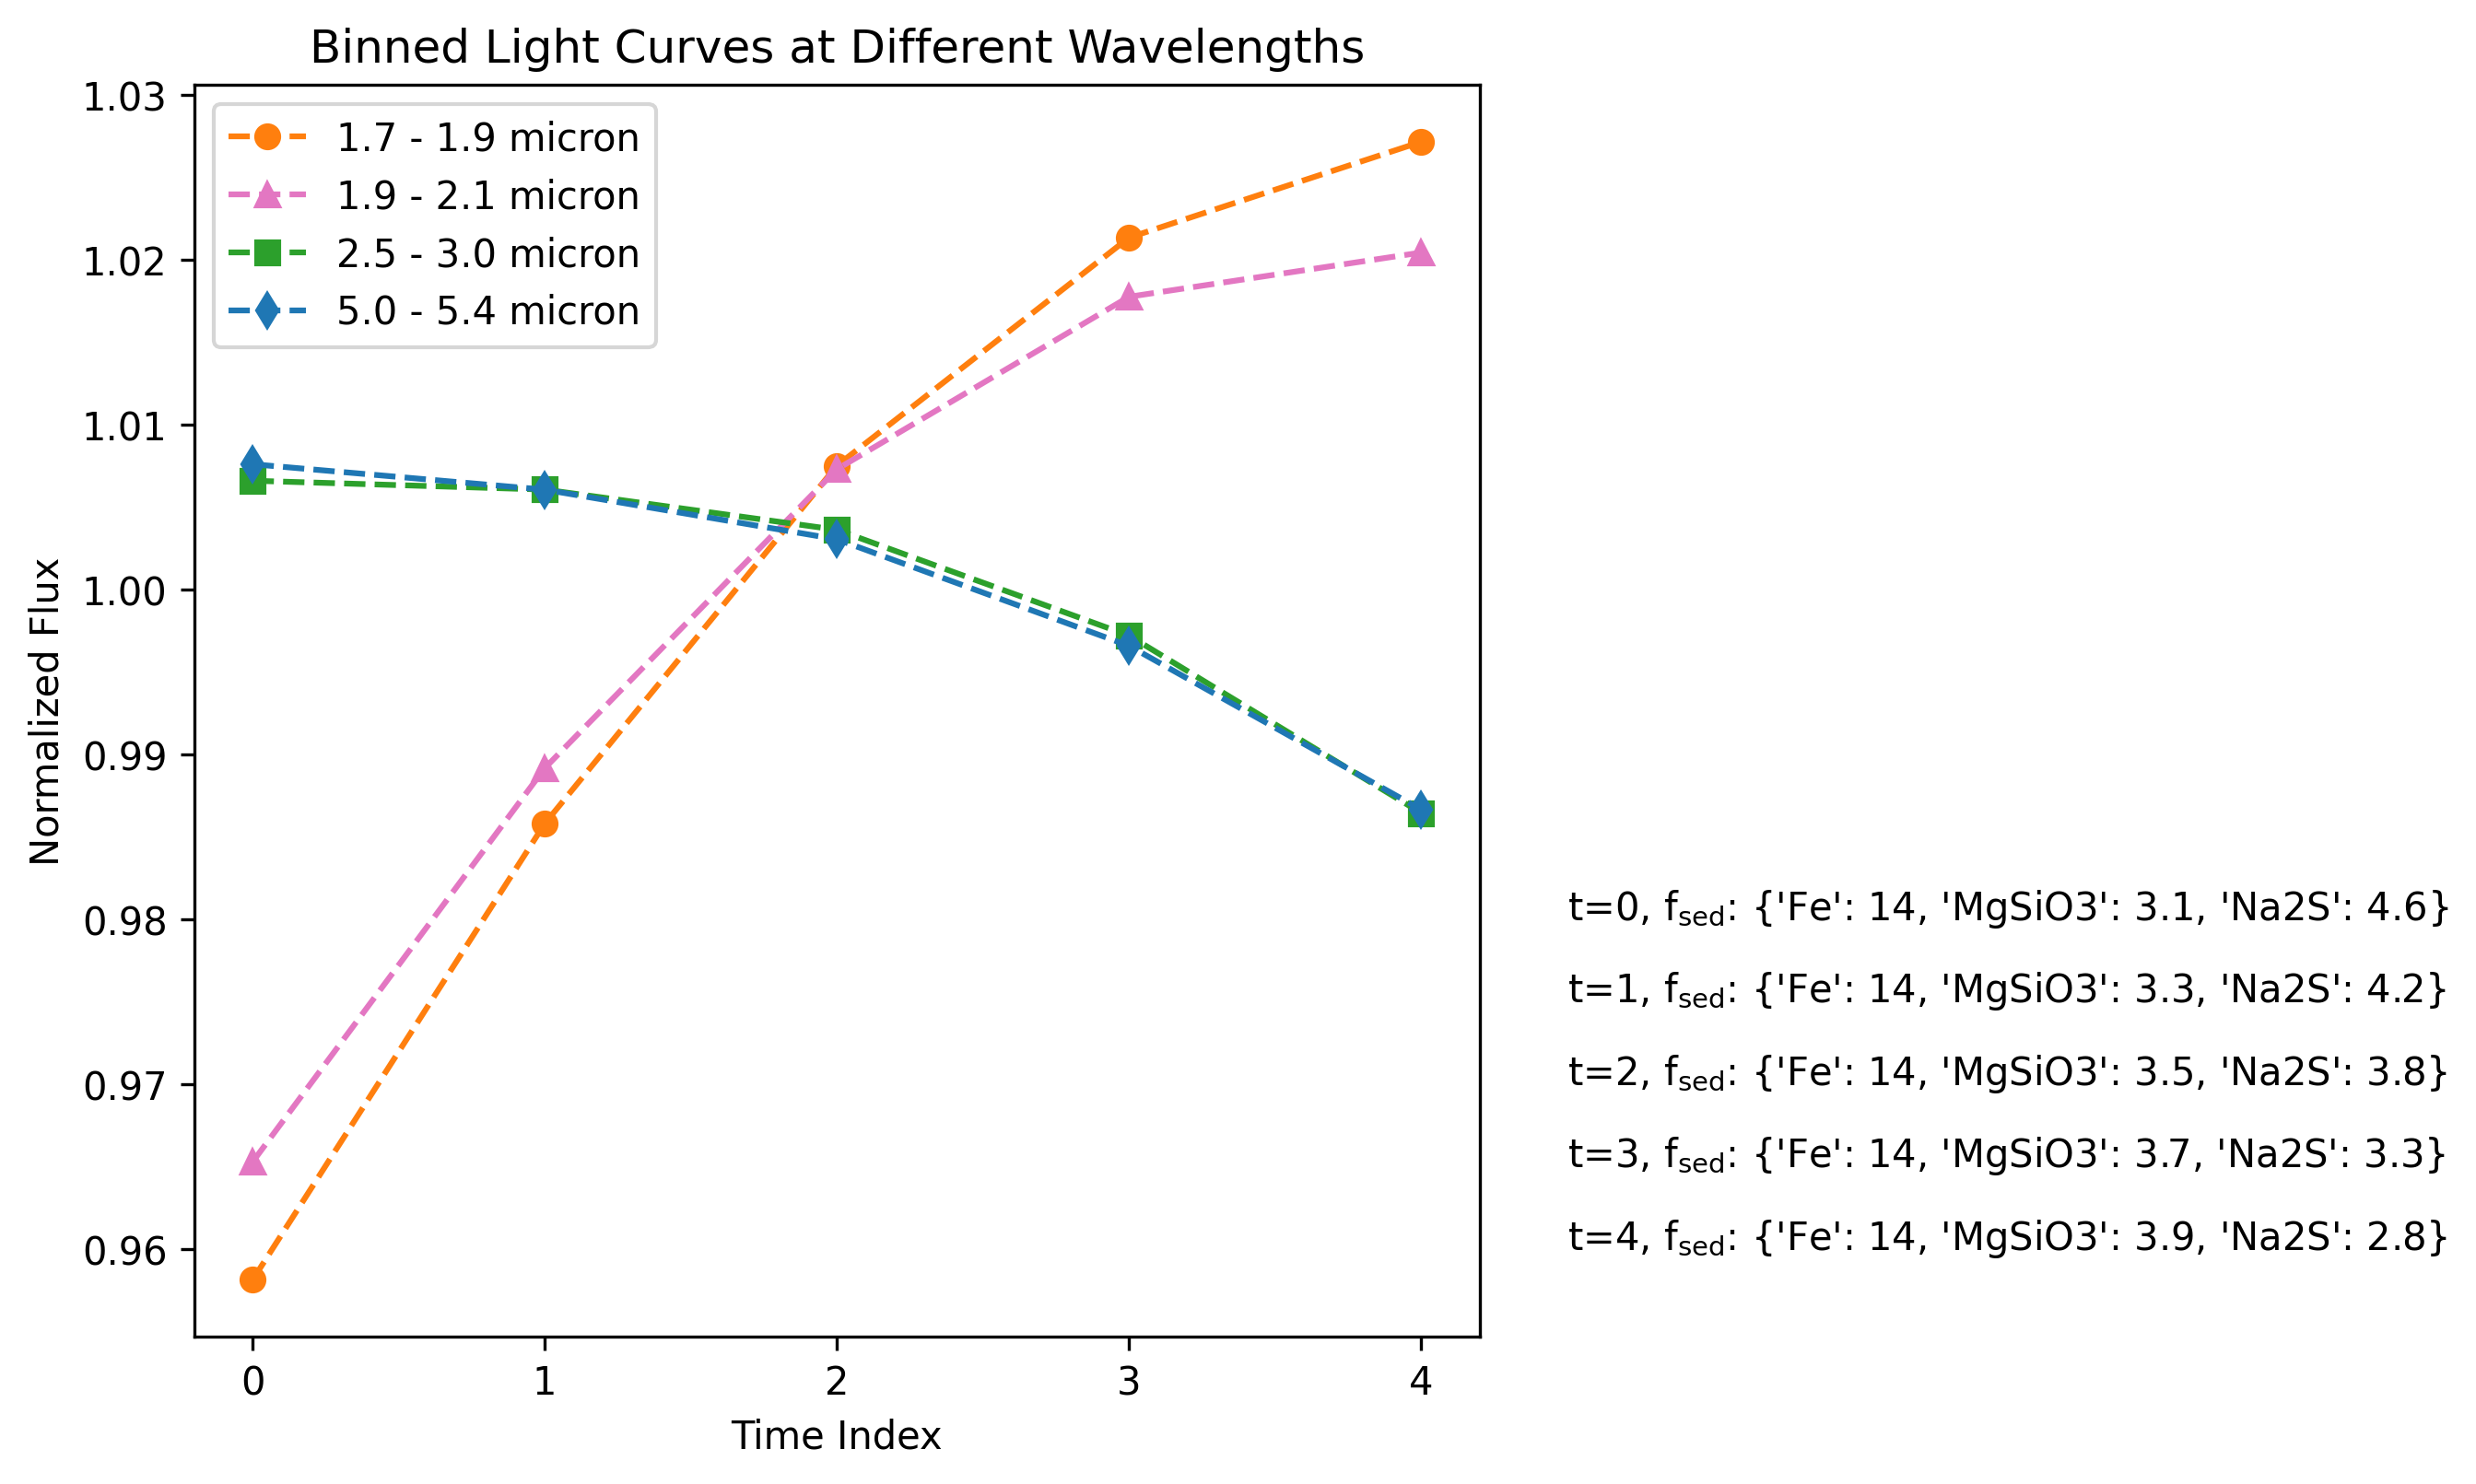

In [74]:
# Get binned light curve at 1.8-2.0 micron AND 2.5-3.0 micron

# fluxes = [np.transpose(y) for y in [y0, y1, y2]]
fluxes = [np.transpose(y) for y in [y0, y1, y2, y3, y4]]

wave = np.transpose(1e4 / x0)  # micron

wavebin1 = (1.7, 1.9)
wavebin2 = (1.9, 2.1)
wavebin3 = (2.5, 3.0)
wavebin4 = (5.0, 5.4) 

flux1, flux2, flux3, flux4 = [], [], [], []
mean1, mean2, mean3, mean4 = 0, 0, 0, 0

for flux in fluxes:
    wavebin1_mask = (wave >= wavebin1[0]) & (wave <= wavebin1[1])
    wavebin2_mask = (wave >= wavebin2[0]) & (wave <= wavebin2[1])
    wavebin3_mask = (wave >= wavebin3[0]) & (wave <= wavebin3[1])
    wavebin4_mask = (wave >= wavebin4[0]) & (wave <= wavebin4[1])

    binned_flux1 = np.median(flux[wavebin1_mask])
    mean1 += binned_flux1
    binned_flux2 = np.median(flux[wavebin2_mask])
    mean2 += binned_flux2

    binned_flux3 = np.median(flux[wavebin3_mask])
    mean3 += binned_flux3
    binned_flux4 = np.median(flux[wavebin4_mask])
    mean4 += binned_flux4

    flux1.append(binned_flux1)
    flux2.append(binned_flux2)
    flux3.append(binned_flux3)
    flux4.append(binned_flux4)

mean1 /= len(fluxes)
mean2 /= len(fluxes)
mean3 /= len(fluxes)
mean4 /= len(fluxes)
time = np.arange(0, len(fluxes))

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
ax.plot(time, flux1/mean1, ls='--', marker='o', c='tab:orange', label=f'{wavebin1[0]} - {wavebin1[1]} micron')
ax.plot(time, flux2/mean2, ls='--', marker='^', c='tab:pink', label=f'{wavebin2[0]} - {wavebin2[1]} micron')
ax.plot(time, flux3/mean3, ls='--', marker='s', c='tab:green', label=f'{wavebin3[0]} - {wavebin3[1]} micron')
ax.plot(time, flux4/mean4, ls='--', marker='d', c='tab:blue', label=f'{wavebin4[0]} - {wavebin4[1]} micron')

# ax.plot(time+4, flux1[::-1]/mean1, ls='--', marker='o', c='tab:orange')
# ax.plot(time+4, flux2[::-1]/mean2, ls='--', marker='^', c='tab:pink')
# ax.plot(time+4, flux3[::-1]/mean3, ls='--', marker='s', c='tab:green')
# ax.plot(time+4, flux4[::-1]/mean4, ls='--', marker='d', c='tab:blue')

ax.set_xlabel('Time Index')
ax.set_ylabel('Normalized Flux')
ax.set_title('Binned Light Curves at Different Wavelengths')

for i, fsedict in enumerate([fsed_dict0, fsed_dict1, fsed_dict2, fsed_dict3, fsed_dict4]):
    ax.text(4.5, 0.98-i*0.005, f't={i},' + r' f$_\mathrm{sed}$: ' + str(fsedict))

ax.legend()
ax.set_xticks(time)
plt.show()
plt.close()

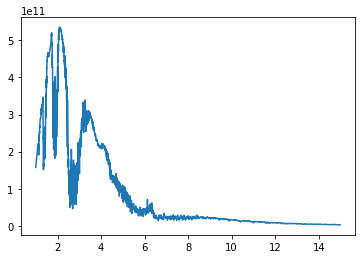

In [25]:
plt.plot(1e4/x0, y0)

In [93]:
### Keep cloud config the same but vary Fe/H ratio to see effect on spectrum

gases = ['Fe', 'MgSiO3']
a, b = 14, 1
fsed_dict0 = {'Fe': a, 'MgSiO3': b+0}
fsed_dict1 = {'Fe': a, 'MgSiO3': b+0}
fsed_dict2 = {'Fe': a, 'MgSiO3': b+0}
colist = [1.0, 1.25, 1.55]

bd_co1, opa_co1, profile_k1 = configure_atm(mh=colist[0], eq=False) # has to set eq true to use chemeq C/O
x_co1, y_co1, cld_out_kco, df_out_co1 = configure_cloud(bd_co1, opa_co1, fsed=fsed_dict0, gases=gases, R=500)

bd_co2, opa_co2, profile_co2 = configure_atm(mh=colist[1], eq=False)
x_co2, y_co2, cld_out_co2, df_out_co2 = configure_cloud(bd_co2, opa_co2, fsed=fsed_dict1, gases=gases, R=500)

bd_co3, opa_co3, profile_co3 = configure_atm(mh=colist[2], eq=False)
x_co3, y_co3, cld_out_co3, df_out_co3 = configure_cloud( bd_co3, opa_co3, fsed=fsed_dict2, gases=gases, R=500)

====== Configured a brown dwarf atmosphere with: ======
Teff: 1200 K, log(g): 4.0, C/O: 0.0, [M/H]: 1.0, kzz: 10000000.0 cm^2/s
Using cloud species: ['Fe', 'MgSiO3']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:1.7818376472825065e-07cm for the 1th gas at the 0th grid point; 2.0633555660913758e-07cm for the 1th gas at the 1th grid point; 2.3874315098881316e-07cm for the 1th gas at the 2th grid point; 2.7602213844294887e-07cm for the 1th gas at the 3th grid point;  Turn off warnings by setting verbose=False.
====== Configured a brown dwarf atmosphere with: ======
Teff: 1200 K, log(g): 4.0, C/O: 0.0, [M/H]: 1.25, kzz: 10000000.0 cm^2/s
Using cloud species: ['Fe', 'MgSiO3']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:1.78183764728250

In [94]:
show(jpi.spectrum([x_co1, x_co2, x_co3], [y_co1, y_co2, y_co3],
                plot_width=1000, plot_height=500,
                y_axis_label='Flux (erg/s/cm^2/Hz)',
                x_axis_label='Wavelength (micron)',
                y_axis_type='linear',
                title='C/O variation for cloudy spectrum',
                legend=[f'Fe/H = {colist[0]}, \n{fsed_dict0}', 
                        f'Fe/H = {colist[1]}, \n{fsed_dict1}', 
                        f'Fe/H = {colist[2]}, \n{fsed_dict2}']))

In [82]:
### Keep cloud config the same but vary kzz to see effect on spectrum

gases = ['Fe', 'MgSiO3']
a, b = 14, 1.2
fsed_dict0 = {'Fe': a, 'MgSiO3': b+0}
fsed_dict1 = {'Fe': a, 'MgSiO3': b+0}
fsed_dict2 = {'Fe': a, 'MgSiO3': b+0}
kzzlist = [1e7, 7e6, 5e6]

bd_k1, opa_k1, profile_k1 = configure_atm(kzz=kzzlist[0])
x_k1, y_k1, cld_out_k1, df_out_k1 = configure_cloud(bd_k1, opa_k1, fsed=fsed_dict0, gases=gases, R=500)

bd_k2, opa_k2, profile_k2 = configure_atm(kzz=kzzlist[1])
x_k2, y_k2, cld_out_k2, df_out_k2 = configure_cloud(bd_k2, opa_k2, fsed=fsed_dict1, gases=gases, R=500)

bd_k3, opa_k3, profile_k3 = configure_atm(kzz=kzzlist[2])
x_k3, y_k3, cld_out_k3, df_out_k3 = configure_cloud(bd_k3, opa_k3, fsed=fsed_dict2, gases=gases, R=500)

====== Configured a brown dwarf atmosphere with: ======
Teff: 1200 K, log(g): 4.0, C/O: 0.0, [M/H]: 1.0, kzz: 10000000.0 cm^2/s
Using cloud species: ['Fe', 'MgSiO3']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:2.209104317828647e-07cm for the 1th gas at the 0th grid point; 2.5544223403135485e-07cm for the 1th gas at the 1th grid point; 2.9512086375258636e-07cm for the 1th gas at the 2th grid point;  Turn off warnings by setting verbose=False.
====== Configured a brown dwarf atmosphere with: ======
Teff: 1200 K, log(g): 4.0, C/O: 0.0, [M/H]: 1.0, kzz: 7000000.0 cm^2/s
Using cloud species: ['Fe', 'MgSiO3']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:1.5421082889516497e-07cm for the 1th gas at the 0th grid point; 1.7835812236112766e

In [ ]:
show(jpi.spectrum([x_k1, x_k2, x_k3], [y_k1, y_k2, y_k3],
                plot_width=1000, plot_height=500,
                y_axis_label='Flux (erg/s/cm^2/cm)',
                x_axis_label='Wavelength (micron)',
                y_axis_type='linear',
                title='C/O variation for cloudy spectrum',
                legend=[f'kzz = {kzzlist[0]}, \n{fsed_dict0}', 
                        f'kzz = {kzzlist[1]}, \n{fsed_dict1}', 
                        f'kzz = {kzzlist[2]}, \n{fsed_dict2}']))

In [44]:
"""TESTING DIFFERENT FSED VALUES FOR DIFFERENT SPECIES"""

gases = ['Fe', 'MgSiO3', 'Mg2SiO4']
a0, b0, c0 = 12,    2.0,    1
a1, b1, c1 = 12,    1.75,    1.25
a2, b2, c2 = 12,    1.5,    1.5

fsed_dict0 = {'Fe': a0, 'MgSiO3': b0, 'Mg2SiO4': c0}
fsed_dict1 = {'Fe': a1, 'MgSiO3': b1, 'Mg2SiO4': c1}
fsed_dict2 = {'Fe': a2, 'MgSiO3': b2, 'Mg2SiO4': c2}

opa_custom = jdi.opannection(wave_range=[1.0, 15.0]) # define wave range

# Dict with same values
x0, y0, cld_out0, df_out0 = configure_cloud(
    bd, opa_custom, fsed=fsed_dict0, R=500,
    gases=gases)

x1, y1, cld_out1, df_out1 = configure_cloud(
    bd, opa_custom, fsed=fsed_dict1, R=500,
    gases=gases)

x2, y2, cld_out2, df_out2 = configure_cloud(
    bd, opa_custom, fsed=fsed_dict2, R=500,
    gases=gases)

Using cloud species: ['Fe', 'MgSiO3', 'Mg2SiO4']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:1.7696241363287198e-07cm for the 2th gas at the 0th grid point; 2.0492184533269938e-07cm for the 2th gas at the 1th grid point; 2.3710811655525808e-07cm for the 2th gas at the 2th grid point; 2.7413264443821275e-07cm for the 2th gas at the 3th grid point;  Turn off warnings by setting verbose=False.
Using cloud species: ['Fe', 'MgSiO3', 'Mg2SiO4']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:2.3021023652349138e-07cm for the 2th gas at the 0th grid point; 2.661111981441556e-07cm for the 2th gas at the 1th grid point; 3.073462444167023e-07cm for the 2th gas at the 2th grid point;  Turn off warnings by setting verbose=False.
Using cloud spec

In [45]:
show(jpi.spectrum([x0, x1, x2], [y0, y1, y2], 
                plot_width=1000, plot_height=500,
                y_axis_label='Flux (erg/s/cm^2/Hz)',
                x_axis_label='Wavelength (micron)',
                y_axis_type='log',
                title='Fsed per-species Comparison: Na2S is anti-correlated with the rest',
                legend=[f'Fsed: fe={a0}, sio3={b0}, sio4={c0}', 
                        f'Fsed: fe={a1}, sio3={b1}, sio4={c1}', 
                        f'Fsed: fe={a2}, sio3={b2}, sio4={c2}']))

In [93]:
"""TESTING DIFFERENT FSED VALUES FOR DIFFERENT SPECIES"""

## Only varying MgSiO3 and Mg2SiO4 fsed values
gases = ['Fe', 'Al2O3', 'MgSiO3', 'Mg2SiO4', 'Na2S']

a, b = 1.4, 2.4
a0, b0 = 1.6, 2.2
a1, b1 = 1.8, 2.0
a2, b2 = 2.0, 1.8
a3, b3 = 2.2, 1.6
a4, b4 = 2.4, 1.4

fsed_dict = {'Fe': a, 'Al2O3': a, 'MgSiO3': b, 'Mg2SiO4': b, 'Na2S': a}
fsed_dict0 = {'Fe': a0, 'Al2O3': a0, 'MgSiO3': b0, 'Mg2SiO4': b0, 'Na2S': a0}
fsed_dict1 = {'Fe': a1, 'Al2O3': a1, 'MgSiO3': b1, 'Mg2SiO4': b1, 'Na2S': a0}
fsed_dict2 = {'Fe': a2, 'Al2O3': a2, 'MgSiO3': b2, 'Mg2SiO4': b2, 'Na2S': a0}
fsed_dict3 = {'Fe': a3, 'Al2O3': a3, 'MgSiO3': b3, 'Mg2SiO4': b3, 'Na2S': a0}
fsed_dict4 = {'Fe': a4, 'Al2O3': a4, 'MgSiO3': b4, 'Mg2SiO4': b4, 'Na2S': a0}

# Dict with same values
x0, y0, cld_out0, df_out0 = configure_cloud(
    bd, opa, fsed=fsed_dict0,
    gases=gases)

x1, y1, cld_out1, df_out1 = configure_cloud(
    bd, opa, fsed=fsed_dict1,
    gases=gases)

x2, y2, cld_out2, df_out2 = configure_cloud(
    bd, opa, fsed=fsed_dict2,
    gases=gases)

x3, y3, cld_out3, df_out3 = configure_cloud(
    bd, opa, fsed=fsed_dict3,
    gases=gases)

x4, y4, cld_out4, df_out4 = configure_cloud(
    bd, opa, fsed=fsed_dict4,
    gases=gases)
    

Using cloud species: ['Fe', 'Al2O3', 'MgSiO3', 'Mg2SiO4', 'Na2S']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:1.2756195209746684e-07cm for the 0th gas at the 0th grid point; 2.4797118237391736e-07cm for the 1th gas at the 0th grid point; 1.4730782446018822e-07cm for the 0th gas at the 1th grid point; 2.8617823521697987e-07cm for the 1th gas at the 1th grid point; 1.6995029611518666e-07cm for the 0th gas at the 2th grid point; 1.9589077466350583e-07cm for the 0th gas at the 3th grid point; 2.2487235191853847e-07cm for the 0th gas at the 4th grid point; 2.5890811038216184e-07cm for the 0th gas at the 5th grid point; 2.9704348882629723e-07cm for the 0th gas at the 6th grid point;  Turn off warnings by setting verbose=False.
Using cloud species: ['Fe', 'Al2O3', 'MgSiO3', 'Mg2SiO4', 'Na2S']
Take caution in analyzing results. There have been a calculated particle

In [ ]:
# show(jpi.spectrum([x0, x1, x2], [y0, y1, y2], 
#                 plot_width=1000, plot_height=500,
#                 y_axis_label='Flux (erg/s/cm^2/Hz)',
#                 x_axis_label='Wavelength (micron)',
#                 y_axis_type='log',
#                 title='Fsed per-species Comparison: Si is anti-correlated with the rest',
#                 legend=[f'fe,na={a0}, si={b0}', 
#                         f'fe,na={a1}, si={b1}', 
#                         f'fe,na={a2}, si={b2}']))

show(jpi.spectrum([x0, x1, x2, x3, x4], [y0, y1, y2, y3, y4],
                plot_width=1000, plot_height=500,
                y_axis_label='Flux (erg/s/cm^2/cm)',
                x_axis_label='Wavelength (micron)',
                y_axis_type='log',
                title='Fsed per-species Comparison: Si is anti-correlated with the rest',
                legend=[f'fe,na={a0}, si={b0}', 
                        f'fe,na={a1}, si={b1}', 
                        f'fe,na={a2}, si={b2}',
                        f'fe,na={a3}, si={b3}',
                        f'fe,na={a4}, si={b4}']))

In [ ]:
out1 = jdi.get_contribution(bd, opa, at_tau=1)

# show(jpi.molecule_contribution(out1, opa, plot_width=700, plot_height=500,
#                                y_axis_label='Flux (erg/s/cm^2/cm)',
#                                x_axis_label='Wavenumber (1/cm)'))
# Plot molecule contribution

figs=[]
for i,it in zip([out1['tau_p_surface']],['bd']):
    wno=[]
    spec=[]
    labels=[]
    for j in i.keys():
        x,y = jdi.mean_regrid(opa.wno, i[j],R=100)
        if np.min(y)<4.5: # Bars
            wno+=[x]
            spec+=[y]
            labels +=[j]
    fig = jpi.spectrum(wno, spec, plot_width=700,plot_height=500,y_axis_label='Tau~1 Pressure (bars)',
                       y_axis_type='log',x_range=[1,5],
                         y_range=[2e2,1e-4],legend=labels)
    fig.title.text=it
    figs+=[fig]
jpi.show(jpi.row(figs))

In [88]:
### Changing fsed: 1: most cloudy, 7: least cloudy 
# fsed: sedimentation efficiency parameter, larger values correspond to thinner clouds with larger particles

tab = {'x':[], 'y':[], 'cld_out':[], 'out':[]}

gases = ['Fe', 'Al2O3', 'MgSiO3', 'Mg2SiO4', 'Na2S']
for fs in [1.8, 2.0, 2.2]:
    x_cldy, y_cldy, cld_out, out = configure_cloud(bd, opa, fsed=fs, gases=gases)
    [tab[key].append(val) for key, val in zip(['x', 'y', 'cld_out', 'out'], [x_cldy, y_cldy, cld_out, out])]
    print('done fsed = ', fs)


Using cloud species: ['Fe', 'Al2O3', 'MgSiO3', 'Mg2SiO4', 'Na2S']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:1.4696213775792874e-07cm for the 0th gas at the 0th grid point; 2.8484647173210616e-07cm for the 1th gas at the 0th grid point; 1.6958089079384564e-07cm for the 0th gas at the 1th grid point; 1.9549004514595287e-07cm for the 0th gas at the 2th grid point; 2.2514028244247766e-07cm for the 0th gas at the 3th grid point; 2.580525073402227e-07cm for the 0th gas at the 4th grid point; 2.968562914545786e-07cm for the 0th gas at the 5th grid point;  Turn off warnings by setting verbose=False.
done fsed =  1.8
Using cloud species: ['Fe', 'Al2O3', 'MgSiO3', 'Mg2SiO4', 'Na2S']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:1.66803679

In [92]:
show(jpi.spectrum(tab['x'], tab['y'],
                  plot_width=1000, plot_height=500,
                  legend=['fsed=1.8', 'fsed=2', 'fsed=2.2'], 
                  y_axis_type='log',
                  title='Cloudy Spectra with Different fsed'))

In [45]:
### Changing fsed: smaller is cloudier
# fsed: sedimentation efficiency parameter, larger values correspond to thinner clouds with larger particles
# test a low gravity case without CH4
tab = {'x':[], 'y':[], 'cld_out':[], 'out':[]}

# test using a lower gravity
bdlow, opalow, profilelow = configure_atm(C_to_O=0.55, Teff=1200, gravity=1000, kzz=1e7, excluded_mol=['CH4'])

for fs in [0.8, 1, 1.25, 1.5]:
    x_cldy, y_cldy, cld_out, out = configure_cloud(bdlow, opalow, fsed=fs, gases='recommended')
    # x_cldy, y_cldy, cld_out, out = configure_cloud(bd, opa, fsed=fs, gases='recommended')
    [tab[key].append(val) for key, val in zip(['x', 'y', 'cld_out', 'out'], [x_cldy, y_cldy, cld_out, out])]
    print('done fsed = ', fs)


====== Configured a brown dwarf atmosphere with: ======
Teff: 1200 K, log(g): 3.0, C/O: 0.55, [M/H]: 1.0, kzz: 10000000.0 cm^2/s
Using cloud species: ['ZnS', 'TiO2', 'NH3', 'Na2S', 'MnS', 'MgSiO3', 'Mg2SiO4', 'KCl', 'H2O', 'Fe', 'Cr', 'CH4', 'CaTiO3', 'Al2O3']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:9.906927685389285e-08cm for the 0th gas at the 0th grid point; 9.417453907144366e-08cm for the 1th gas at the 0th grid point; 2.1570485837779715e-07cm for the 3th gas at the 0th grid point; 1.0005987546194663e-07cm for the 4th gas at the 0th grid point; 1.2540030361055827e-07cm for the 5th gas at the 0th grid point; 1.245419937758193e-07cm for the 6th gas at the 0th grid point; 2.0116536991750662e-07cm for the 7th gas at the 0th grid point; 5.0811996941482425e-08cm for the 9th gas at the 0th grid point; 5.5963434665944154e-08cm for the 10th gas at the 0th gr

In [46]:
show(jpi.spectrum(tab['x'], tab['y'],
                  plot_width=1000, plot_height=500,
                  legend=['fsed=0.8', 'fsed=1', 'fsed=1.25', 'fsed=1.5'], 
                  title='Cloudy Spectra with Different fsed'))

In [59]:
### Changing fsed: smaller is cloudier
# fsed: sedimentation efficiency parameter, larger values correspond to thinner clouds with larger particles
# changing temperature to see where methane appears
tab = {'x':[], 'y':[], 'cld_out':[], 'out':[]}

# test using a lower gravity
bdl, opal, profilel = configure_atm(C_to_O=0.55, Teff=1200, gravity=250, kzz=1e7)

for fs in [0.8, 1, 1.25, 1.5]:
    x_cldy, y_cldy, cld_out, out = configure_cloud(bdl, opal, fsed=fs, gases='recommended')
    # x_cldy, y_cldy, cld_out, out = configure_cloud(bd, opa, fsed=fs, gases='recommended')
    [tab[key].append(val) for key, val in zip(['x', 'y', 'cld_out', 'out'], [x_cldy, y_cldy, cld_out, out])]
    print('done fsed = ', fs)


====== Configured a brown dwarf atmosphere with: ======
Teff: 1200 K, log(g): 2.3979400086720375, C/O: 0.55, [M/H]: 1.0, kzz: 10000000.0 cm^2/s
Using cloud species: ['Al2O3', 'CaTiO3', 'Cr', 'Fe', 'KCl', 'Mg2SiO4', 'MgSiO3', 'MnS', 'Na2S', 'TiO2', 'ZnS']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:8.610163281008552e-08cm for the 0th gas at the 0th grid point; 8.610163281008552e-08cm for the 1th gas at the 0th grid point; 4.801077533068625e-08cm for the 2th gas at the 0th grid point; 4.359082629247518e-08cm for the 3th gas at the 0th grid point; 1.7250317940098633e-07cm for the 4th gas at the 0th grid point; 1.068097776615223e-07cm for the 5th gas at the 0th grid point; 1.0754592873562499e-07cm for the 6th gas at the 0th grid point; 8.582180446025959e-08cm for the 7th gas at the 0th grid point; 1.8495756077204446e-07cm for the 8th gas at the 0th grid point; 

In [60]:
show(jpi.spectrum(tab['x'], tab['y'],
                  plot_width=1000, plot_height=500,
                  legend=['fsed=0.8', 'fsed=1', 'fsed=1.25', 'fsed=1.5'], 
                  title='Cloudy Spectra with Different fsed'))

In [19]:
print('Cloud Optical Depth at 1 mbar for fsed = 0.8, 1, 1.25, 1.5')
for cld_out in tab['cld_out']:
    show(vjpi.all_optics(cld_out))

Cloud Optical Depth at 1 mbar for fsed = 0.8, 1, 1.25, 1.5


In [21]:
tab['cld_out'][0].keys()

dict_keys(['pressure', 'pressure_unit', 'temperature', 'temperature_unit', 'wave', 'wave_unit', 'condensate_mmr', 'cond_plus_gas_mmr', 'mean_particle_r', 'droplet_eff_r', 'r_units', 'column_density', 'column_density_unit', 'opd_per_layer', 'single_scattering', 'asymmetry', 'opd_by_gas', 'condensibles', 'scalar_inputs', 'fsed', 'altitude', 'layer_thickness', 'z_unit', 'mixing_length', 'mixing_length_unit', 'kz', 'kz_unit', 'scale_height', 'cloud_deck'])

In [23]:
from bokeh.models import LinearColorMapper, LogTicker,BasicTicker, ColorBar,LogColorMapper,Legend
from bokeh.palettes import magma as colfun1
from bokeh.palettes import viridis as colfun2
from bokeh.layouts import gridplot

print('Cloud Optical Depth at 1 mbar for fsed = 4, 4.25, 4.5, 5')
# Create a list to store all the figures
figures = []

for cld_out in tab['cld_out']:
    dat01 = vjdi.picaso_format(cld_out['opd_per_layer'], cld_out['single_scattering'],
                               cld_out['asymmetry'])

    nwno = len(cld_out['wave'])
    nlayer = len(cld_out['pressure'])
    pressure = cld_out['pressure']

    pressure_label = 'Pressure (Bars)'
    wavelength_label = 'Wavelength (um)'
    wavelength = cld_out['wave']

    cols = colfun1(200)
    color_mapper = LinearColorMapper(palette=cols, low=0, high=1)

    # PLOT OPD
    scat01 = np.flip(np.reshape(dat01['opd'].values, (nlayer, nwno)), 0)

    xr, yr = scat01.shape
    cols = colfun2(200)[::-1]
    color_mapper = LogColorMapper(palette=cols, low=1e-3, high=10)

    f01 = figure(x_range=[0, yr], y_range=[0, xr],
                 x_axis_label=wavelength_label, y_axis_label=pressure_label,
                 title="Cloud Optical Depth Per Layer",
                 width=350, height=400)

    f01.image(image=[scat01], color_mapper=color_mapper, x=0, y=0, dh=xr, dw=yr)

    color_bar = ColorBar(color_mapper=color_mapper, ticker=LogTicker(),
                         label_standoff=12, border_line_color=None, location=(0, 0))
    f01.add_layout(color_bar, 'left')

    #CHANGE X AND Y AXIS TO BE PHYSICAL UNITS 
    #indexes for pressure plot 
    if (pressure is not None):
        pressure = ["{:.1E}".format(i) for i in pressure[::-1]] #flip since we are also flipping matrices
        npres = len(pressure)
        ipres = np.array(range(npres))
        #set how many we actually want to put on the figure 
        #hard code ten on each.. 
        ipres = ipres[::int(npres/10)]
        pressure = pressure[::int(npres/10)]
        #create dictionary for tick marks 
        ptick = {int(i):j for i,j in zip(ipres,pressure)}
        for i in [f01]:
            i.yaxis.ticker = ipres
            i.yaxis.major_label_overrides = ptick
    if (wavelength is not None):
        wave = ["{:.1F}".format(i) for i in wavelength]
        nwave = len(wave)
        iwave = np.array(range(nwave))
        iwave = iwave[::int(nwave/10)]
        wave = wave[::int(nwave/10)]
        wtick = {int(i):j for i,j in zip(iwave,wave)}
        for i in [f01]:
            i.xaxis.ticker = iwave
            i.xaxis.major_label_overrides = wtick 

    figures.append(f01)

# Arrange the figures in a grid layout with n columns
n = len(tab['cld_out'])  # Number of columns
grid = gridplot([figures[i:i + n] for i in range(0, len(figures), n)])

show(grid)


Cloud Optical Depth at 1 mbar for fsed = 4, 4.25, 4.5, 5


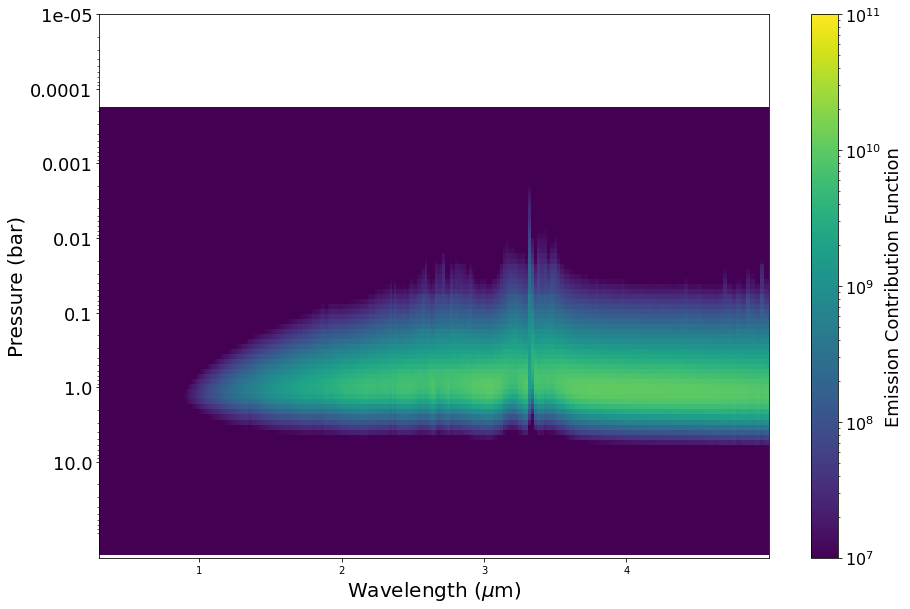

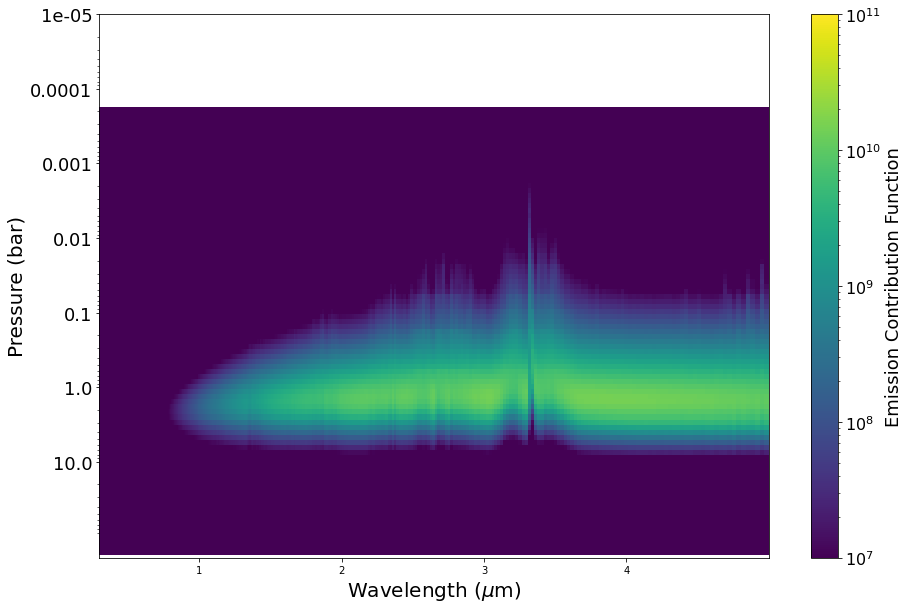

In [24]:
# thermal contribution function of different fsed: 0.8 and 1.
for i, out in enumerate(tab['out'][:2]):
    fig, ax, CF = jpi.thermal_contribution(out['full_output'], 
                                              norm=jpi.colors.LogNorm(vmin=1e7, vmax=1e11), R=150)


In [25]:
### Changing kzz
# kzz: vertical eddy diffusion coefficient, larger values correspond to stronger mixing and thicker clouds
# stronger vertical mixing, less efficient sedimentation, less cloudy

xarray, yarray, outarray = [], [], []
for kzzz in [1e5, 1e7, 1e9]:

    bd, opa, pf = configure_atm(C_to_O=0.55, mh=1.0, kzz=kzzz)
    
    # set fsed=1 for thick clouds
    x_cldy, y_cldy, cld_out, out = configure_cloud(bd, opa, fsed=1, gases='recommended')

    xarray.append(x_cldy), yarray.append(y_cldy), outarray.append(out)
    print('done kzz = ', kzzz)

show(jpi.spectrum(xarray, yarray,plot_width=1000, plot_height=500,
                  legend=['Kzz=1e5','Kzz=1e7', 'Kzz=1e9']))

====== Configured a brown dwarf atmosphere with: ======
Teff: 1200 K, log(g): 4.0, C/O: 0.55, [M/H]: 1.0, kzz: 100000.0 cm^2/s
Using cloud species: ['ZnS', 'TiO2', 'NH3', 'Na2S', 'MnS', 'MgSiO3', 'Mg2SiO4', 'KCl', 'H2O', 'Fe', 'Cr', 'CH4', 'CaTiO3', 'Al2O3']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:1.3853622102024562e-09cm for the 0th gas at the 0th grid point; 1.318393077996185e-09cm for the 1th gas at the 0th grid point; 3.011343859539457e-09cm for the 3th gas at the 0th grid point; 1.3992313400002195e-09cm for the 4th gas at the 0th grid point; 1.7538816413769923e-09cm for the 5th gas at the 0th grid point; 1.7418618364387279e-09cm for the 6th gas at the 0th grid point; 2.808345086681804e-09cm for the 7th gas at the 0th grid point; 7.126140486777216e-10cm for the 9th gas at the 0th grid point; 7.841059589761419e-10cm for the 10th gas at the 0th grid p

In [ ]:
### Changing kzz
# kzz: vertical eddy diffusion coefficient, larger values correspond to stronger mixing and thicker clouds
# stronger vertical mixing, less efficient sedimentation, less cloudy

# smaller kzz change
xarray, yarray, outarray = [], [], []
for kzzz in [5e6, 8e6, 1e7, 2e7]:

    bd, opa, pf = configure_atm(C_to_O=0.55, mh=1.0, kzz=kzzz)

    # set fsed the same
    x_cldy, y_cldy, cld_out, out = configure_cloud(bd, opa, fsed=1, gases='recommended')

    xarray.append(x_cldy), yarray.append(y_cldy), outarray.append(out)

    print('done kzz = ', kzzz)

====== Configured a brown dwarf atmosphere with: ======
Teff: 1200 K, log(g): 4.0, C/O: 0.55, [M/H]: 1.0, kzz: 5000000.0 cm^2/s
Using cloud species: ['Al2O3', 'CaTiO3', 'Cr', 'Fe', 'KCl', 'Mg2SiO4', 'MgSiO3', 'MnS', 'Na2S', 'TiO2', 'ZnS']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:7.110692546793531e-08cm for the 0th gas at the 0th grid point; 7.110692546793529e-08cm for the 1th gas at the 0th grid point; 3.974110658134284e-08cm for the 2th gas at the 0th grid point; 3.613525648705439e-08cm for the 3th gas at the 0th grid point; 1.4211943150081943e-07cm for the 4th gas at the 0th grid point; 8.824489603347916e-08cm for the 5th gas at the 0th grid point; 8.885424449239666e-08cm for the 6th gas at the 0th grid point; 7.087538743973015e-08cm for the 7th gas at the 0th grid point; 1.523945236146061e-07cm for the 8th gas at the 0th grid point; 6.682171055521692e

In [72]:
show(jpi.spectrum(xarray, yarray,plot_width=1000, plot_height=500,
                  legend=['Kzz=5e6','Kzz=8e6', 'Kzz=1e7', 'Kzz=2e7']))

In [21]:
### Changing metalicity, cloudy, fsed=1
# higher metallicity, higher temperature, less efficient cloud formation, less cloudy?

xarray2, yarray2, outarray = [], [], []
for c2o in [0.0, 0.121, 0.224, 0.412]:
    bd, opa, pf = configure_atm(C_to_O=c2o, eq=True) #chemical equilibrium for this test to use C/O ratio
    x_cldy, y_cldy, cld_out, out = configure_cloud(bd, opa, fsed=1.2, gases=['Fe', 'MgSiO3'])
    xarray2.append(x_cldy), yarray2.append(y_cldy), outarray.append(out)
    print('done C/O = ', c2o)

show(jpi.spectrum(xarray2,
                     yarray2,plot_width=1000, plot_height=400,
                  legend=['C/O=0.', 'C/O=0.1', 'C/O=0.2', 'C/O=0.4'],))

====== Configured a brown dwarf atmosphere with: ======
Teff: 1200 K, log(g): 4.0, C/O: 0.0, [M/H]: 1.0, kzz: 10000000.0 cm^2/s
Using cloud species: ['Fe', 'MgSiO3']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:9.027128029241593e-08cm for the 0th gas at the 0th grid point; 2.209104317828647e-07cm for the 1th gas at the 0th grid point; 1.044403163491814e-07cm for the 0th gas at the 1th grid point; 2.5544223403135485e-07cm for the 1th gas at the 1th grid point; 1.2073001302218108e-07cm for the 0th gas at the 2th grid point; 2.9512086375258636e-07cm for the 1th gas at the 2th grid point; 1.394425136811315e-07cm for the 0th gas at the 3th grid point; 1.606671571846058e-07cm for the 0th gas at the 4th grid point; 1.8537258075199396e-07cm for the 0th gas at the 5th grid point; 2.133843656038799e-07cm for the 0th gas at the 6th grid point; 2.458691894484051e-07cm f

In [38]:
fig, dndr = vjpi.radii(cld_out,at_pressure=1e-3)
show(fig)

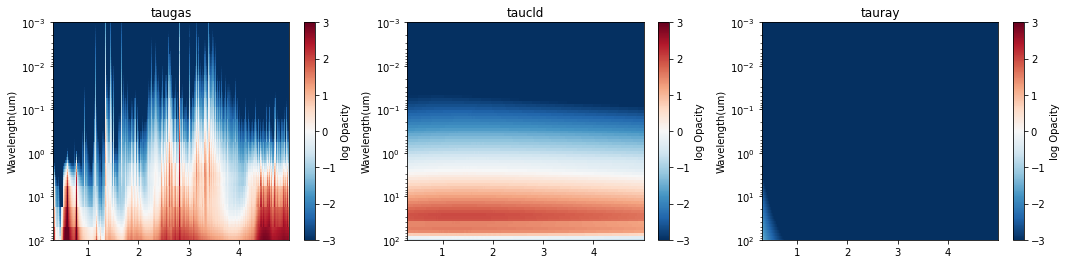

In [39]:
jpi.heatmap_taus(out)#['full_output'])

In [ ]:
### Changing fsed: smaller is cloudier
# fsed: sedimentation efficiency parameter, larger values correspond to thinner clouds with larger particles
# changing temperature to see where methane appears
tab = {'x':[], 'y':[], 'cld_out':[], 'out':[]}

# test using a log[g]=4 gravity

for fs in [1.0, 1.05, 1.1, 1.15]:
    x_cldy, y_cldy, cld_out, out = configure_cloud(bd, opa, fsed=fs, gases='recommended')
    [tab[key].append(val) for key, val in zip(['x', 'y', 'cld_out', 'out'], [x_cldy, y_cldy, cld_out, out])]
    print('done fsed = ', fs)


Using cloud species: ['Al2O3', 'CaTiO3', 'Cr', 'Fe', 'KCl', 'Mg2SiO4', 'MgSiO3', 'MnS', 'Na2S', 'TiO2', 'ZnS']
Take caution in analyzing results. There have been a calculated particle radii off the Mie grid, which has a min radius of 1e-08cm and distribution of 2. The following errors:1.426079664446073e-07cm for the 0th gas at the 0th grid point; 1.426079664446073e-07cm for the 1th gas at the 0th grid point; 7.973081435180878e-08cm for the 2th gas at the 0th grid point; 7.250668959330075e-08cm for the 3th gas at the 0th grid point; 2.848515562724555e-07cm for the 4th gas at the 0th grid point; 1.7696241363287198e-07cm for the 5th gas at the 0th grid point; 1.7818376472825065e-07cm for the 6th gas at the 0th grid point; 1.4214377844168723e-07cm for the 7th gas at the 0th grid point; 3.054297291241391e-07cm for the 8th gas at the 0th grid point; 1.3403421479051343e-07cm for the 9th gas at the 0th grid point; 1.40734253273315e-07cm for the 10th gas at the 0th grid point; 1.651543004600049

In [69]:
show(jpi.spectrum(tab['x'], tab['y'],
                  plot_width=1000, plot_height=500,
                  legend=['fsed=1.0', 'fsed=1.05', 'fsed=1.10', 'fsed=1.15'], 
                  title='Cloudy Spectra with Different fsed'))